# Modelado — House Prices

Elige el modelo que mejor predice `SalePrice` mediante un **torneo de ocho candidatos**:
regresiones lineales, ensambles de árboles y una red neuronal. Cada uno se optimiza con
**validación cruzada de 10 pliegues** y todos se comparan después contra el mismo conjunto de
validación, que ninguno vio durante el ajuste.

## Las dos reglas que estructuran el notebook

Todo lo demás es consecuencia de estas dos.

**1. Nada de fuga de datos.** Un transformador que aprende de los datos con los que luego se
mide da una estimación optimista y falsa. Por eso este notebook **no lee
`data/processed/train_features.csv`**: ese archivo salió de un pipeline ajustado con las 1458
filas completas, así que su escalado, sus percentiles de recorte y sus medianas de imputación
ya vieron todas las filas. Usarlo contaminaría cada pliegue de la validación cruzada. En su
lugar se parte de `data/raw/` y el pipeline de características se **re-ajusta dentro de cada
pliegue**.

**2. Nada de sobreajuste sin medir.** No basta con evitarlo: hay que poder verlo. Se reporta la
brecha entre el error de entrenamiento y el de validación cruzada de cada modelo, se incluye
una regresión sin regularizar como testigo de cómo se ve el sobreajuste, y el conjunto de
validación se mantiene intacto hasta el torneo final.

## Estructura

| # | Sección | Qué hace |
|---|---|---|
| 1 | Datos | Carga desde `raw`, quita los 2 outliers, transforma el target |
| 2 | Partición | 80 % entrenamiento / 20 % validación, estratificada por precio |
| 3 | Arquitectura | El pipeline que impide la fuga |
| 4 | Métricas | RMSE logarítmico, RMSE real y RMSE normalizado al rango |
| 5 | Candidatos | Los 8 modelos y sus rejillas de hiperparámetros |
| 6 | Torneo | `GridSearchCV` con `KFold(10)` sobre cada candidato |
| 7 | Tabla | Comparación numérica y diagnóstico de sobreajuste |
| 8 | Gráficas | Siete figuras que comparan a los ocho candidatos |
| 9 | Ganador | Curva de aprendizaje e importancia por permutación |
| 10 | Guardado | El modelo del torneo, la tabla, y el modelo de producción |
| 11 | MLflow | Registro del experimento y alias champion/challenger |
| 12 | Conclusiones | Qué se decidió y qué queda abierto |

In [1]:
import logging
import os
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import mlflow
from mlflow.tracking import MlflowClient
import numpy as np
import pandas as pd
import yaml

# El paquete del proyecto vive en la raíz, un nivel arriba de notebooks/.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from sklearn.base import clone
from sklearn.ensemble import (
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import make_scorer, mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, learning_curve, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline

# joblib necesita esta clase en el espacio de nombres para recargar el pipeline guardado.
from house_pricing.features import RellenarAnioGaraje  # noqa: F401

RAW_DIR = RAIZ / "data" / "raw"
PROCESSED_DIR = RAIZ / "data" / "processed"
MODELS_DIR = RAIZ / "models"
REPORTS_DIR = RAIZ / "reports"

SEMILLA = 42
K_PLIEGUES = 10
PROPORCION_VALIDACION = 0.20
N_JOBS = -1   # -1 usa todos los núcleos; ponerlo en 1 si el kernel muere por las DLLs de BLAS

# --- MLflow ---
# El backend es SQLite y no el almacén de archivos (`./mlruns`) porque el Model
# Registry —y por tanto los alias champion/challenger— no funciona sobre archivos.
# Verificado contra esta versión: el intento devuelve "The filesystem tracking
# backend is in maintenance mode".
MLFLOW_URI = f"sqlite:///{(RAIZ / 'mlflow.db').as_posix()}"
EXPERIMENTO = "house_pricing_torneo"
MODELO_REGISTRADO = "house_pricing"

# Las figuras se guardan según se crean, para poder adjuntarlas al run de MLflow
# sin tener que volver a dibujarlas.
FIGURAS = {}

# MLflow habla mucho: una barra de progreso por artefacto descargado y un aviso de
# seguridad cada vez que guarda un modelo con cloudpickle. El aviso es legítimo
# —cloudpickle ejecuta código al deserializar— y está explicado en la sección 11,
# pero repetirlo ocho veces no añade nada. Se silencia la repetición, no el hecho.
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"
logging.getLogger("mlflow.sklearn").setLevel(logging.ERROR)

# Convergencia de Lasso y del MLP: avisan mucho y no aporta verlos cientos de veces.
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*did not converge.*")

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

print("raíz del proyecto:", RAIZ)
print(f"semilla {SEMILLA} · {K_PLIEGUES} pliegues · validación {PROPORCION_VALIDACION:.0%}")
print(f"mlflow: {MLFLOW_URI}")

2026/11/05 20:38:40 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at C:\Users\dgarc\anaconda3\envs\env_house_pricing\Lib\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


2026-11-05 20:38:44.325 | INFO     | house_pricing.config:<module>:11 - PROJ_ROOT path is: C:\Users\dgarc\OneDrive\Escritorio\Maestria\4T_2026\Product_Mang\Clase_Cloud\house_pricing


raíz del proyecto: C:\Users\dgarc\OneDrive\Escritorio\Maestria\4T_2026\Product_Mang\Clase_Cloud\house_pricing
semilla 42 · 10 pliegues · validación 20%
mlflow: sqlite:///C:/Users/dgarc/OneDrive/Escritorio/Maestria/4T_2026/Product_Mang/Clase_Cloud/house_pricing/mlflow.db


### Convención visual de las figuras

Las figuras de la sección 8 comparten una paleta fija, validada para visión con deficiencia de
color. El color codifica **la familia del modelo**, no su posición en el ranking: si el orden
cambia, los colores no se mueven, y eso permite seguir a un mismo modelo entre figuras.

| Familia | Color |
|---|---|
| Regresión lineal | azul `#2a78d6` |
| Ensamble de árboles | naranja `#eb6834` |
| Red neuronal | aguamarina `#1baf7a` |

In [2]:
# Paleta categórica validada (las 3 primeras ranuras: separación segura en todos los pares).
COLOR_FAMILIA = {
    "Regresión lineal": "#2a78d6",
    "Ensamble de árboles": "#eb6834",
    "Red neuronal": "#1baf7a",
}
TINTA = "#0b0b0b"           # texto primario
TINTA_SUAVE = "#52514e"     # texto secundario
SUPERFICIE = "#fcfcfb"      # fondo de la figura
REJILLA = "#e4e3df"         # rejilla, deliberadamente recesiva

mpl.rcParams.update({
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
    "axes.edgecolor": REJILLA,
    "axes.labelcolor": TINTA_SUAVE,
    "axes.titlecolor": TINTA,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",   # DejaVu Sans no tiene semibold y matplotlib avisa
    "axes.titlelocation": "left",
    "axes.titlepad": 10,
    "axes.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": REJILLA,
    "grid.linewidth": 0.8,
    "grid.linestyle": "-",      # las rejillas punteadas añaden ruido visual
    "xtick.color": TINTA_SUAVE,
    "ytick.color": TINTA_SUAVE,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.frameon": False,
    "legend.fontsize": 8.5,
    "lines.linewidth": 2.0,
    "figure.dpi": 110,
})


def miles(x, _=None):
    """Formatea dólares como 185k, que se lee mejor que 185000 en un eje."""
    return f"{x / 1000:,.0f}k"


print("estilo configurado")

estilo configurado


## 1. Datos — por qué se parte de `raw` y no de `processed`

Se repiten aquí los dos primeros pasos del notebook 3.0 —cargar y quitar los outliers de
fila— porque son los únicos que **no pueden** vivir dentro de un pipeline: eliminar filas
cambia el número de observaciones, y un transformador de scikit-learn debe devolver tantas
filas como recibe.

Los Id **524** y **1299** salen por la razón documentada en `ESTADO_PROYECTO.md`: son casas de
calidad 10 y más de 4000 pies² vendidas por menos de 200 mil con `SaleCondition = Partial`
(obra sin terminar). Su precio no describe el inmueble, así que como ejemplos de entrenamiento
son ruido. Los Id 692 y 1183, igual de grandes pero coherentes en precio, se quedan: sostienen
el extremo alto del rango.

**El target se modela en logaritmo.** `log1p(SalePrice)` baja el sesgo de 1.88 a 0.12 y es la
métrica oficial de la competencia. Esto importa más de lo que parece: en escala original un
error de 50 mil sobre una casa de 500 mil pesa igual que sobre una de 100 mil, aunque el
primero sea un 10 % y el segundo un 50 %. El logaritmo convierte el error absoluto en error
relativo, que es lo que de verdad interesa al tasar.

Las **30 variables de entrada** son las que seleccionó el notebook 3.0, leídas de
`features_seleccionadas.yaml`. Entran crudas, tal como vienen del CSV: el pipeline se encarga
del resto.

In [3]:
config = yaml.safe_load(
    (PROCESSED_DIR / "features_seleccionadas.yaml").read_text(encoding="utf-8")
)
FEATURES = config["MODEL_FEATURES"]
CONTINUAS = config["FEATURE_GROUPS"]["continuas"]
DISCRETAS = config["FEATURE_GROUPS"]["discretas"]
CATEGORICAS = config["FEATURE_GROUPS"]["categoricas"]

train_crudo = pd.read_csv(RAW_DIR / "train.csv")

IDS_OUTLIERS = [524, 1299]
antes = len(train_crudo)
train_crudo = train_crudo[~train_crudo["Id"].isin(IDS_OUTLIERS)].reset_index(drop=True)

X = train_crudo[FEATURES].copy()
y_real = train_crudo["SalePrice"].to_numpy()
y = np.log1p(y_real)          # el target con el que se entrena

print(f"filas: {antes} -> {len(train_crudo)} ({antes - len(train_crudo)} outliers fuera)")
print(f"features de entrada: {len(FEATURES)} ({len(CONTINUAS)} continuas + "
      f"{len(DISCRETAS)} discretas + {len(CATEGORICAS)} categóricas)")
print(f"\ntarget en dólares : media {y_real.mean():>10,.0f} · sesgo {pd.Series(y_real).skew():.2f}")
print(f"target en log1p   : media {y.mean():>10.3f} · sesgo {pd.Series(y).skew():.2f}")

filas: 1460 -> 1458 (2 outliers fuera)
features de entrada: 30 (10 continuas + 10 discretas + 10 categóricas)

target en dólares : media    180,933 · sesgo 1.88
target en log1p   : media     12.024 · sesgo 0.12


## 2. Partición — 80 % entrenamiento / 20 % validación

El proyecto no tenía conjunto de validación: `test_features.csv` es el test de Kaggle y **no
trae `SalePrice`**, así que no sirve para medir nada. Se construye aquí.

**Estratificada por quintiles de precio.** Una partición aleatoria simple de 1458 filas puede,
por azar, dejar las casas caras mal repartidas, y el extremo alto del rango es justo donde los
modelos sufren. Estratificar por quintil garantiza que ambos lados vean la misma mezcla de
precios. Con 292 filas de validación un quintil son ~58 casas: suficiente para que la media no
dependa de dos observaciones.

**El 20 % no se toca hasta la sección 6.** La optimización de hiperparámetros ocurre entera
dentro del 80 %, mediante los 10 pliegues. Si se eligieran los hiperparámetros mirando el
conjunto de validación, ese conjunto pasaría a ser parte del entrenamiento y su RMSE dejaría de
ser una estimación honesta del error en datos nuevos — el modo más común de engañarse a uno
mismo al comparar modelos.

In [4]:
# Quintiles del precio: 5 grupos de igual tamaño, de las casas más baratas a las más caras.
estratos = pd.qcut(y_real, q=5, labels=False)

X_entrena, X_valida, y_entrena, y_valida, estr_entrena, estr_valida = train_test_split(
    X, y, estratos,
    test_size=PROPORCION_VALIDACION,
    random_state=SEMILLA,
    stratify=estratos,
)

# El rango del target real en validación: el denominador del RMSE normalizado.
y_valida_real = np.expm1(y_valida)
RANGO_VALIDACION = float(y_valida_real.max() - y_valida_real.min())

reparto = pd.DataFrame({
    "entrenamiento": pd.Series(estr_entrena).value_counts(normalize=True).sort_index(),
    "validacion": pd.Series(estr_valida).value_counts(normalize=True).sort_index(),
}).mul(100).round(1)
reparto.index = [f"quintil {i + 1}" for i in reparto.index]

print(f"entrenamiento: {len(X_entrena)} filas · validación: {len(X_valida)} filas")
print(f"\nprecio en validación: {y_valida_real.min():,.0f} a {y_valida_real.max():,.0f} "
      f"-> rango {RANGO_VALIDACION:,.0f}")
print(f"media {y_valida_real.mean():,.0f} · mediana {np.median(y_valida_real):,.0f}")
print("\nreparto por quintil de precio (%):")
print(reparto.to_string())

entrenamiento: 1166 filas · validación: 292 filas

precio en validación: 37,900 a 538,000 -> rango 500,100
media 175,937 · mediana 161,500

reparto por quintil de precio (%):
           entrenamiento  validacion
quintil 1           20.2        20.2
quintil 2           20.2        20.2
quintil 3           19.6        19.5
quintil 4           20.2        20.2
quintil 5           19.8        19.9


## 3. Arquitectura — el pipeline que impide la fuga

Esta sección es el corazón del notebook. El objeto que se evalúa **no es un modelo**: es un
pipeline de dos pasos.

```
Pipeline([
    ("features", <el pipeline de 13 pasos del notebook 3.0>),
    ("modelo",   <el estimador que se esté probando>),
])
```

El primer paso se carga desde `models/pipeline_features.joblib` y se **clona** con
`sklearn.base.clone`, que copia la configuración y descarta todo lo aprendido. Un clon es un
pipeline sin ajustar.

**Por qué esto elimina la fuga.** Cuando `GridSearchCV` entrena un pliegue, llama a `fit` sobre
el pipeline completo con 9/10 de los datos. En esa llamada:

- `StandardScaler` calcula su media y su desviación con esos 9/10;
- `Winsorizer` calcula los percentiles 1 y 99 con esos 9/10;
- `MeanMedianImputer` y `CategoricalImputer` calculan su mediana y su moda con esos 9/10;
- `YeoJohnsonTransformer` estima su lambda con esos 9/10;
- `OneHotEncoder` aprende los niveles presentes en esos 9/10.

El pliegue restante solo pasa por `transform`, que **aplica** parámetros ya fijados sin
recalcular nada. Repetido diez veces, el resultado es un error de validación cruzada que
ninguna transformación vio venir. Comparado con leer `train_features.csv`, el costo es tiempo:
el pipeline se reajusta en cada pliegue y en cada configuración del grid.

**Y resuelve un segundo problema de golpe.** Como el pipeline recibe las 30 columnas crudas, la
importancia por permutación de la sección 9 se mide sobre **variables reales** —
`Neighborhood`, no `Neighborhood_NridgHt` repartido en 25 dummies.

In [5]:
pipeline_features = joblib.load(MODELS_DIR / "pipeline_features.joblib")

print(f"pipeline de características: {len(pipeline_features.steps)} pasos")
for i, (nombre, transformador) in enumerate(pipeline_features.steps, 1):
    print(f"{i:2}. {nombre:22} {type(transformador).__name__}")


def construir(estimador):
    """Envuelve un estimador con un clon sin ajustar del pipeline de características."""
    return Pipeline([("features", clone(pipeline_features)), ("modelo", estimador)])


# Comprobación 1: el clon no conserva nada de lo que aprendió el notebook 3.0.
# Por convención de scikit-learn, los atributos aprendidos terminan en guion bajo.
clon = clone(pipeline_features)
aprendidos = [f"{paso}.{a}" for paso, trans in clon.steps for a in vars(trans)
              if a.endswith("_") and not a.startswith("_")]
assert not aprendidos, f"el clon llegó con parámetros aprendidos: {aprendidos}"

# Comprobación 2: ajustado con el 80 %, produce columnas idénticas para ambos lados.
prueba = clone(pipeline_features).fit(X_entrena, y_entrena)
cols_entrena = prueba.transform(X_entrena)
cols_valida = prueba.transform(X_valida)
assert list(cols_entrena.columns) == list(cols_valida.columns), "columnas descompensadas"
assert cols_valida.isna().sum().sum() == 0, "quedan NaN en validación"

print("\nel clon llega sin ajustar ✓")
print(f"30 features crudas -> {cols_entrena.shape[1]} columnas para el modelo")
print(f"entrenamiento {cols_entrena.shape} · validación {cols_valida.shape} · sin NaN ✓")

pipeline de características: 13 pasos
 1. indicador_sin_garaje   AddMissingIndicator
 2. anio_garaje            RellenarAnioGaraje
 3. estructural_cat        CategoricalImputer
 4. estructural_num        ArbitraryNumberImputer
 5. aleatorio_5_a_20       RandomSampleImputer
 6. mediana_hasta_5        MeanMedianImputer
 7. moda_hasta_5           CategoricalImputer
 8. ordinal                SklearnTransformerWrapper
 9. one_hot                OneHotEncoder
10. recorte_percentiles    Winsorizer
11. log_sin_ceros          LogCpTransformer
12. yeo_johnson            YeoJohnsonTransformer
13. escalado               SklearnTransformerWrapper



el clon llega sin ajustar ✓
30 features crudas -> 122 columnas para el modelo
entrenamiento (1166, 122) · validación (292, 122) · sin NaN ✓


## 4. Métricas — tres números para el mismo error

Los modelos se entrenan sobre `log1p(SalePrice)`, así que su error natural está en logaritmos.
Pero un RMSE de 0.13 no le dice nada a nadie que quiera comprar una casa. Se reportan tres
métricas, y cada una responde a una pregunta distinta.

**1. RMSE logarítmico — la métrica de selección.**

$$\text{RMSE}_{\log} = \sqrt{\frac{1}{n}\sum \left(\log(1+\hat{y}) - \log(1+y)\right)^2}$$

Es la métrica oficial de la competencia y la que decide el ganador del torneo. Al medir sobre
logaritmos pondera el error **relativo**: equivocarse un 10 % cuesta lo mismo en una casa de
100 mil que en una de 500 mil. Como número suelto es casi un error porcentual —0.13 ≈ 13 %.

**2. RMSE real — la métrica interpretable.** Se deshace el logaritmo con `expm1` en los **dos**
lados y se mide en dólares:

$$\text{RMSE}_{\text{real}} = \sqrt{\frac{1}{n}\sum \left(\text{expm1}(\hat{y}_{\log}) - y\right)^2}$$

El orden importa: **no** se puede convertir un RMSE logarítmico en dólares multiplicando por
nada. Hay que volver cada predicción a su escala y recién entonces promediar los errores, que
es lo que hace la función de abajo.

Un detalle honesto: `expm1` de una predicción en logaritmos devuelve algo parecido a la
*mediana* condicional, no a la media, así que el RMSE real queda levemente sesgado a la baja
respecto a un modelo entrenado directamente en dólares. No se corrige (existe el factor de
*smearing* de Duan) porque corregirlo optimizaría una métrica distinta de la que la competencia
evalúa, y el objetivo aquí es elegir modelo, no ganar centavos.

**3. RMSE normalizado al rango — la métrica comparable.**

$$\text{NRMSE} = \frac{\text{RMSE}_{\text{real}}}{y_{\max} - y_{\min}}$$

Divide el error en dólares por la amplitud del target en validación, lo que lo deja sin
unidades y permite comparar contra otros datasets o contra el mismo dataset en otra moneda. Su
debilidad es el denominador: el rango depende de **dos** observaciones, la más cara y la más
barata, así que una sola casa extrema lo mueve. Por eso se usa como complemento y nunca como
criterio de decisión.

In [6]:
def rmse(y_cierto, y_predicho):
    """RMSE simple, en las unidades en que se le pase."""
    return float(np.sqrt(mean_squared_error(y_cierto, y_predicho)))


def rmse_dolares(y_log_cierto, y_log_predicho):
    """RMSE en dólares a partir de predicciones logarítmicas.

    Deshace log1p en ambos lados ANTES de restar: un RMSE logarítmico no se
    convierte a dólares con un factor, hay que volver a la escala original primero.
    """
    return rmse(np.expm1(y_log_cierto), np.expm1(y_log_predicho))


def medir(y_log_cierto, y_log_predicho, rango):
    """Las tres métricas de una tirada de predicciones."""
    en_dolares = rmse_dolares(y_log_cierto, y_log_predicho)
    return {
        "rmse_log": rmse(y_log_cierto, y_log_predicho),
        "rmse_real": en_dolares,
        "nrmse_rango": en_dolares / rango,
    }


# GridSearchCV mide ambas en cada pliegue; `refit` usará rmse_log para elegir.
# greater_is_better=False hace que scikit-learn guarde el valor negado, de modo que
# "mayor es mejor" siga valiendo internamente: por eso luego se les cambia el signo.
METRICAS = {
    "rmse_log": "neg_root_mean_squared_error",
    "rmse_real": make_scorer(rmse_dolares, greater_is_better=False),
}

# Verificación con un predictor trivial: predecir siempre la mediana del entrenamiento.
mediana_log = np.median(y_entrena)
base = medir(y_valida, np.full_like(y_valida, mediana_log), RANGO_VALIDACION)
print("referencia tonta (predecir siempre la mediana):")
print(f"  rmse_log    {base['rmse_log']:.4f}")
print(f"  rmse_real   {base['rmse_real']:>10,.0f} USD")
print(f"  nrmse_rango {base['nrmse_rango']:.4f}  ({base['nrmse_rango']:.2%} del rango)")
print("\ncualquier modelo del torneo debe quedar muy por debajo de estos números.")

referencia tonta (predecir siempre la mediana):
  rmse_log    0.3864
  rmse_real       68,272 USD
  nrmse_rango 0.1365  (13.65% del rango)

cualquier modelo del torneo debe quedar muy por debajo de estos números.


## 5. Los ocho candidatos

Tres familias, y una razón para cada miembro.

| # | Modelo | Familia | Por qué está | Configuraciones |
|---|---|---|---|---|
| 1 | Regresión lineal (OLS) | Regresión | **Testigo de sobreajuste.** Sin regularización, 122 columnas y 1166 filas: debería ajustar el entrenamiento mejor que nadie y generalizar peor | 1 (no tiene qué ajustar) |
| 2 | Ridge | Regresión | Penaliza el cuadrado de los coeficientes. Encoge sin descartar, lo que le sienta bien a predictoras correlacionadas como `GarageArea`/`GarageCars` | 7 valores de `alpha` |
| 3 | Lasso | Regresión | Penaliza el valor absoluto, así que lleva coeficientes a cero: es selección de variables incorporada. Responde a la reserva nº 4 del `ESTADO_PROYECTO.md` | 6 valores de `alpha` |
| 4 | ElasticNet | Regresión | Mezcla las dos penalizaciones. `l1_ratio` decide cuánto de cada una | 7 × 3 = 21 |
| 5 | Random Forest | Ensamble | Promedia árboles profundos decorrelacionados. Captura no linealidades e interacciones sin que haya que escribirlas | 3 × 3 = 9 |
| 6 | Gradient Boosting | Ensamble | Árboles secuenciales, cada uno corrigiendo el residuo del anterior. Suele ganar en datos tabulares | 2 × 2 × 2 = 8 |
| 7 | Hist Gradient Boosting | Ensamble | Boosting con histogramas, mucho más rápido. Permite explorar más regularización por el mismo tiempo | 2 × 2 × 2 = 8 |
| 8 | Red neuronal (MLP) | Red neuronal | Perceptrón multicapa. Es la familia que peor le sienta a 1166 filas, y el torneo debe poder mostrarlo | 2 × 3 = 6 |

Son **66 configuraciones**, cada una evaluada en 10 pliegues: 660 ajustes del pipeline
completo. El candidato 1 es el único con una sola configuración, y es deliberado: no tiene
hiperparámetros que optimizar porque su falta de regularización es precisamente lo que se
quiere observar.

### Cómo se eligieron las rejillas

**Las rejillas están centradas en la regularización, no en la capacidad.** En Ridge, Lasso y
ElasticNet se barre `alpha` en escala logarítmica, que es como se comporta: la diferencia entre
0.1 y 1 importa, entre 100 y 100.5 no. En los ensambles se mueven `min_samples_leaf`,
`max_features`, `subsample`, `max_leaf_nodes` y `l2_regularization` —todos frenos— en vez de
subir la profundidad. Ampliar la capacidad en un dataset de 1166 filas solo compra sobreajuste.

**La red neuronal se calibró antes de armar la rejilla.** Una primera prueba con la
configuración habitual (`alpha=0.0001`, dos capas de 64 y 32) dio RMSE log 0.232, casi el doble
que Ridge. El problema no era la arquitectura sino la regularización: con `alpha=1.0` el error
bajó a 0.163. La rejilla final barre `alpha` en torno a ese valor en vez de explorar
arquitecturas grandes que estos datos no sostienen.

**`early_stopping=True` en el MLP.** Reserva un 15 % del pliegue de entrenamiento y corta
cuando ese trozo deja de mejorar durante 30 épocas. Es regularización por parada temprana, y
—esto importa— el 15 % sale de los datos de entrenamiento del pliegue, nunca del pliegue de
validación.

**Random Forest con `n_jobs=1`.** El paralelismo se gasta en `GridSearchCV`, que reparte
configuraciones y pliegues. Si además cada bosque abriera sus propios procesos, los dos niveles
competirían por los mismos núcleos y el resultado sería más lento, no más rápido.

In [7]:
# El orden es fijo y se respeta en todas las figuras: el color sigue a la familia,
# no al puesto en el ranking.
CANDIDATOS = {
    "Regresión lineal": {
        "familia": "Regresión lineal",
        "estimador": LinearRegression(),
        "grid": {},
        "eje": None,
    },
    "Ridge": {
        "familia": "Regresión lineal",
        "estimador": Ridge(random_state=SEMILLA),
        "grid": {"alpha": [0.1, 1.0, 3.0, 10.0, 30.0, 100.0, 300.0]},
        "eje": "alpha",
    },
    "Lasso": {
        "familia": "Regresión lineal",
        "estimador": Lasso(max_iter=20000, random_state=SEMILLA),
        "grid": {"alpha": [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03]},
        "eje": "alpha",
    },
    "ElasticNet": {
        "familia": "Regresión lineal",
        "estimador": ElasticNet(max_iter=20000, random_state=SEMILLA),
        # El barrido llega hasta 0.0001 porque en una corrida previa el óptimo cayó
        # en 0.001, que era el borde inferior de la rejilla: la comprobación de la
        # figura 7 lo detectó y la rejilla se amplió.
        "grid": {"alpha": [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1],
                 "l1_ratio": [0.1, 0.5, 0.9]},
        "eje": "alpha",
    },
    "Random Forest": {
        "familia": "Ensamble de árboles",
        "estimador": RandomForestRegressor(n_estimators=400, random_state=SEMILLA, n_jobs=1),
        "grid": {"max_features": ["sqrt", 0.3, 0.5], "min_samples_leaf": [1, 2, 4]},
        "eje": "min_samples_leaf",
    },
    "Gradient Boosting": {
        "familia": "Ensamble de árboles",
        "estimador": GradientBoostingRegressor(learning_rate=0.05, random_state=SEMILLA),
        "grid": {"n_estimators": [300, 600], "max_depth": [2, 3], "subsample": [0.8, 1.0]},
        "eje": "n_estimators",
    },
    "Hist Gradient Boosting": {
        "familia": "Ensamble de árboles",
        "estimador": HistGradientBoostingRegressor(max_iter=500, early_stopping=True,
                                                   random_state=SEMILLA),
        "grid": {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31],
                 "l2_regularization": [0.0, 1.0]},
        "eje": "learning_rate",
    },
    "Red neuronal (MLP)": {
        "familia": "Red neuronal",
        "estimador": MLPRegressor(learning_rate_init=0.005, max_iter=3000,
                                  early_stopping=True, n_iter_no_change=30,
                                  validation_fraction=0.15, random_state=SEMILLA),
        "grid": {"hidden_layer_sizes": [(100, 50), (256,)], "alpha": [0.3, 1.0, 3.0]},
        "eje": "alpha",
    },
}

total = 0
print(f"{'modelo':24} {'familia':20} configuraciones")
for nombre, spec in CANDIDATOS.items():
    n = int(np.prod([len(v) for v in spec["grid"].values()])) if spec["grid"] else 1
    total += n
    print(f"{nombre:24} {spec['familia']:20} {n:>3}")
print(f"\n{total} configuraciones × {K_PLIEGUES} pliegues = {total * K_PLIEGUES} ajustes "
      "del pipeline completo")

modelo                   familia              configuraciones
Regresión lineal         Regresión lineal       1
Ridge                    Regresión lineal       7
Lasso                    Regresión lineal       6
ElasticNet               Regresión lineal      21
Random Forest            Ensamble de árboles    9
Gradient Boosting        Ensamble de árboles    8
Hist Gradient Boosting   Ensamble de árboles    8
Red neuronal (MLP)       Red neuronal           6

66 configuraciones × 10 pliegues = 660 ajustes del pipeline completo


## 6. El torneo

Cada candidato pasa por un `GridSearchCV` con el **mismo objeto `KFold`**: mismos diez cortes,
en el mismo orden, para todos. Eso convierte la comparación en una competencia justa — si cada
modelo viera una partición distinta, parte de la diferencia entre ellos sería el azar del
corte.

Tres detalles del montaje:

- **`shuffle=True`** mezcla antes de cortar. `train.csv` viene ordenado por `Id`, y aunque no
  parezca haber tendencia temporal, no barajar es arriesgarse a que los pliegues capten alguna
  estructura del orden original.
- **`refit="rmse_log"`** elige la mejor configuración por la métrica oficial y vuelve a
  entrenar con el 80 % completo. El objeto resultante, `best_estimator_`, es el que después
  predice sobre validación.
- **`return_train_score=True`** guarda también el error **dentro** de cada pliegue de
  entrenamiento. Es lo que permite calcular la brecha entrenamiento → validación cruzada, el
  diagnóstico de sobreajuste de la sección 7.

Después de la búsqueda —y solo después— se predice sobre el 20 % reservado. Esa es la primera
y única vez que el conjunto de validación interviene.

In [8]:
# El mismo objeto para todos los candidatos: mismos cortes, comparación justa.
cv = KFold(n_splits=K_PLIEGUES, shuffle=True, random_state=SEMILLA)

busquedas = {}        # el GridSearchCV ajustado de cada modelo
pliegues = {}         # los 10 RMSE logarítmicos de la mejor configuración
predicciones = {}     # predicciones sobre validación, en logaritmo
filas = []

print(f"{'modelo':24} {'rmse_log CV':>12} {'rmse_log val':>13} {'rmse_real val':>15} "
      f"{'seg':>7}")
print("-" * 76)

for nombre, spec in CANDIDATOS.items():
    grid = {f"modelo__{clave}": valores for clave, valores in spec["grid"].items()}

    busqueda = GridSearchCV(
        construir(spec["estimador"]),
        param_grid=grid,
        scoring=METRICAS,
        refit="rmse_log",          # la métrica oficial decide
        cv=cv,
        n_jobs=N_JOBS,
        return_train_score=True,   # para medir la brecha de sobreajuste
    )

    inicio = time.perf_counter()
    busqueda.fit(X_entrena, y_entrena)
    duracion = time.perf_counter() - inicio

    resultados = busqueda.cv_results_
    mejor = busqueda.best_index_

    # Los 10 pliegues de la mejor configuración, desnegados.
    por_pliegue = np.array([-resultados[f"split{k}_test_rmse_log"][mejor]
                            for k in range(K_PLIEGUES)])

    # Ahora sí: el conjunto de validación, por primera vez.
    prediccion = busqueda.predict(X_valida)
    val = medir(y_valida, prediccion, RANGO_VALIDACION)

    busquedas[nombre] = busqueda
    pliegues[nombre] = por_pliegue
    predicciones[nombre] = prediccion

    filas.append({
        "modelo": nombre,
        "familia": spec["familia"],
        "rmse_log_entrena": -resultados["mean_train_rmse_log"][mejor],
        "rmse_log_cv": -resultados["mean_test_rmse_log"][mejor],
        "rmse_log_cv_sd": resultados["std_test_rmse_log"][mejor],
        "rmse_real_cv": -resultados["mean_test_rmse_real"][mejor],
        "rmse_log_val": val["rmse_log"],
        "rmse_real_val": val["rmse_real"],
        "nrmse_rango_val": val["nrmse_rango"],
        "configuraciones": len(resultados["params"]),
        "segundos": duracion,
        "mejor_config": ", ".join(f"{k.replace('modelo__', '')}={v}"
                                  for k, v in busqueda.best_params_.items()) or "sin ajustar",
    })

    print(f"{nombre:24} {-resultados['mean_test_rmse_log'][mejor]:>12.4f} "
          f"{val['rmse_log']:>13.4f} {val['rmse_real']:>15,.0f} {duracion:>7.1f}")

torneo = pd.DataFrame(filas).set_index("modelo")
print("-" * 76)
print(f"\ntiempo total: {torneo['segundos'].sum() / 60:.1f} min")

modelo                    rmse_log CV  rmse_log val   rmse_real val     seg
----------------------------------------------------------------------------


Regresión lineal               0.1338        0.1445          21,228    21.9


Ridge                          0.1271        0.1425          20,371    27.6


Lasso                          0.1265        0.1399          20,127    21.7


ElasticNet                     0.1261        0.1401          20,042    64.5


Random Forest                  0.1332        0.1538          22,240   127.0


Gradient Boosting              0.1259        0.1438          20,282    80.1


Hist Gradient Boosting         0.1336        0.1538          22,384    44.6


Red neuronal (MLP)             0.1374        0.1447          21,503   129.9
----------------------------------------------------------------------------

tiempo total: 8.6 min


## 7. La tabla del torneo

Dos lecturas de la misma tabla.

**La columna que decide** es `rmse_log_cv`: el promedio de los diez pliegues, calculado sin que
ninguna transformación viera los datos con los que se midió. Va con su desviación entre
pliegues, que importa tanto como la media — un modelo con 0.125 ± 0.030 es menos fiable que uno
con 0.130 ± 0.010, porque su ventaja cabe dentro de su propio ruido.

**La columna que delata** es `brecha`, la distancia entre el error dentro del entrenamiento y el
error en validación cruzada:

$$\text{brecha} = \text{RMSE}_{\log}^{\text{CV}} - \text{RMSE}_{\log}^{\text{entrena}}$$

Un modelo que memoriza sus datos tiene un error de entrenamiento muy bajo y uno de validación
cruzada alto: brecha grande. Un modelo bien regularizado tiene los dos parecidos. La brecha no
es buena ni mala por sí sola —siempre es positiva— pero comparada entre modelos de la misma
tabla distingue al que generaliza del que memoriza.

La última columna, `coherencia`, compara el RMSE logarítmico de validación cruzada con el del
conjunto de validación. Si los dos coinciden, la estimación de la validación cruzada era
confiable y el 20 % reservado no trae sorpresas. Si difieren mucho, la partición fue
afortunada o desafortunada, y conviene desconfiar de las dos cifras.

In [9]:
tabla = pd.DataFrame({
    "familia": torneo["familia"],
    "rmse_log_cv": torneo["rmse_log_cv"].round(4),
    "sd_pliegues": torneo["rmse_log_cv_sd"].round(4),
    "rmse_log_entrena": torneo["rmse_log_entrena"].round(4),
    "brecha": (torneo["rmse_log_cv"] - torneo["rmse_log_entrena"]).round(4),
    "rmse_log_val": torneo["rmse_log_val"].round(4),
    "rmse_real_val": torneo["rmse_real_val"].round(0),
    "nrmse_%": (torneo["nrmse_rango_val"] * 100).round(2),
    "coherencia": (torneo["rmse_log_val"] - torneo["rmse_log_cv"]).round(4),
    "config": torneo["configuraciones"],
    "seg": torneo["segundos"].round(0),
}).sort_values("rmse_log_cv")

MEJOR_CV = tabla.index[0]        # el mejor promedio; la sección 7.1 decide si es el ganador

print("ordenada por rmse_log_cv (la métrica de selección):\n")
print(tabla.to_string())

print(f"\nmejor promedio de validación cruzada: {MEJOR_CV} "
      f"({tabla.loc[MEJOR_CV, 'rmse_log_cv']:.4f})")

print("\nmejor configuración de cada candidato:")
for nombre in tabla.index:
    print(f"  {nombre:24} {torneo.loc[nombre, 'mejor_config']}")

ordenada por rmse_log_cv (la métrica de selección):

                                    familia  rmse_log_cv  sd_pliegues  rmse_log_entrena  brecha  rmse_log_val  rmse_real_val  nrmse_%  coherencia  config    seg
modelo                                                                                                                                                          
Gradient Boosting       Ensamble de árboles       0.1259       0.0136            0.0745  0.0514        0.1438        20282.0     4.06      0.0179       8   80.0
ElasticNet                 Regresión lineal       0.1261       0.0092            0.1170  0.0090        0.1401        20042.0     4.01      0.0140      21   64.0
Lasso                      Regresión lineal       0.1265       0.0102            0.1153  0.0112        0.1399        20127.0     4.02      0.0134       6   22.0
Ridge                      Regresión lineal       0.1271       0.0105            0.1163  0.0107        0.1425        20371.0     4.07      0.0

## 7.1 La regla de 1 error estándar

Tomar el mejor promedio y declararlo ganador tiene un problema: **un promedio viene con
ruido**, y la diferencia entre los primeros puestos suele ser más pequeña que ese ruido. Si el
primero le gana al segundo por menos de lo que su propia cifra tiembla entre pliegues, lo que
se está premiando es el azar del corte, no el modelo.

La regla de 1 error estándar —propuesta por Breiman para árboles de clasificación y hoy
práctica estándar— resuelve eso en dos pasos:

1. Calcular el **error estándar** del mejor modelo: $SE = \sigma_{\text{pliegues}} / \sqrt{k}$,
   donde $\sigma$ es la desviación de sus diez pliegues. Es la incertidumbre de su promedio,
   no la dispersión de los datos.
2. Declarar **empatados** a todos los modelos cuyo RMSE de validación cruzada caiga dentro de
   ese margen, y entre los empatados quedarse con el **más simple**.

**"Más simple" aquí se mide, no se opina.** La definición clásica —menos parámetros, menos
profundidad— no permite comparar un bosque con una regresión penalizada: no hay una escala
común. En su lugar se usa la **brecha de sobreajuste** que ya calcula la tabla, la distancia
entre el error de entrenamiento y el de validación cruzada. Es una cantidad medida sobre estos
datos, comparable entre familias, y mide exactamente lo que la regla busca evitar: el modelo
que pagó su ajuste memorizando.

El criterio queda escrito como código y no como juicio: si los números cambian, la decisión
cambia sola.

In [10]:
# Paso 1: el margen de empate, construido con el error estándar del mejor promedio.
error_estandar = torneo.loc[MEJOR_CV, "rmse_log_cv_sd"] / np.sqrt(K_PLIEGUES)
umbral = torneo.loc[MEJOR_CV, "rmse_log_cv"] + error_estandar

empatados = tabla[tabla["rmse_log_cv"] <= umbral].copy()

# Paso 2: entre los empatados, el de menor brecha de sobreajuste.
GANADOR = empatados["brecha"].idxmin()

print(f"mejor promedio      {MEJOR_CV}  ({torneo.loc[MEJOR_CV, 'rmse_log_cv']:.4f})")
print(f"desviación entre pliegues  {torneo.loc[MEJOR_CV, 'rmse_log_cv_sd']:.4f}")
print(f"error estándar (sd/√{K_PLIEGUES})      {error_estandar:.4f}")
print(f"umbral de empate           {umbral:.4f}")

print(f"\nempatados dentro del margen ({len(empatados)} de {len(tabla)}), "
      "ordenados por brecha de sobreajuste:\n")
print(empatados.sort_values("brecha")[
    ["rmse_log_cv", "sd_pliegues", "brecha", "rmse_log_val", "rmse_real_val", "nrmse_%"]
].to_string())

print(f"\n{'=' * 78}")
print(f"GANADOR: {GANADOR}")
print(f"{'=' * 78}")
fila = torneo.loc[GANADOR]
print(f"configuración    {fila['mejor_config']}")
print(f"rmse_log CV      {fila['rmse_log_cv']:.4f} ± {fila['rmse_log_cv_sd']:.4f}")
print(f"rmse_log val     {fila['rmse_log_val']:.4f}")
print(f"rmse_real val    {fila['rmse_real_val']:,.0f} USD")
print(f"nrmse al rango   {fila['nrmse_rango_val']:.4f}  ({fila['nrmse_rango_val']:.2%})")
print(f"brecha           {fila['rmse_log_cv'] - fila['rmse_log_entrena']:.4f}")

if GANADOR == MEJOR_CV:
    print("\nLa regla confirma al mejor promedio: también es el de menor brecha.")
else:
    ventaja = tabla.loc[GANADOR, "rmse_log_cv"] - tabla.loc[MEJOR_CV, "rmse_log_cv"]
    proporcion = ventaja / torneo.loc[MEJOR_CV, "rmse_log_cv_sd"]
    veces = tabla.loc[MEJOR_CV, "brecha"] / tabla.loc[GANADOR, "brecha"]
    print(f"\nLa regla cambió la decisión:")
    print(f"  {MEJOR_CV} tenía el mejor promedio, por {ventaja:.4f} de RMSE logarítmico.")
    print(f"  Esa ventaja es el {proporcion:.0%} de su propia desviación entre pliegues: "
          "cabe entera dentro de su ruido.")
    print(f"  Y a cambio su brecha de sobreajuste es {veces:.1f} veces la de {GANADOR}.")
    print(f"  En el 20 % reservado, {GANADOR} queda en "
          f"{tabla.loc[GANADOR, 'rmse_log_val']:.4f} y {MEJOR_CV} en "
          f"{tabla.loc[MEJOR_CV, 'rmse_log_val']:.4f}.")

mejor promedio      Gradient Boosting  (0.1259)
desviación entre pliegues  0.0136
error estándar (sd/√10)      0.0043
umbral de empate           0.1302

empatados dentro del margen (4 de 8), ordenados por brecha de sobreajuste:



                   rmse_log_cv  sd_pliegues  brecha  rmse_log_val  rmse_real_val  nrmse_%
modelo                                                                                   
ElasticNet              0.1261       0.0092  0.0090        0.1401        20042.0     4.01
Ridge                   0.1271       0.0105  0.0107        0.1425        20371.0     4.07
Lasso                   0.1265       0.0102  0.0112        0.1399        20127.0     4.02
Gradient Boosting       0.1259       0.0136  0.0514        0.1438        20282.0     4.06

GANADOR: ElasticNet
configuración    alpha=0.001, l1_ratio=0.5
rmse_log CV      0.1261 ± 0.0092
rmse_log val     0.1401
rmse_real val    20,042 USD
nrmse al rango   0.0401  (4.01%)
brecha           0.0090

La regla cambió la decisión:
  Gradient Boosting tenía el mejor promedio, por 0.0002 de RMSE logarítmico.
  Esa ventaja es el 1% de su propia desviación entre pliegues: cabe entera dentro de su ruido.
  Y a cambio su brecha de sobreajuste es 5.7 veces l

## 8. Gráficas de desempeño

Siete figuras, cada una respondiendo a una pregunta que la tabla sola no contesta.

| Figura | Pregunta |
|---|---|
| 1 | ¿Cuánto se equivoca cada modelo, en dólares? |
| 2 | ¿Es estable esa cifra, o depende del pliegue que le tocó? |
| 3 | ¿Memoriza o generaliza? |
| 4 | ¿Se puede confiar en la estimación de la validación cruzada? |
| 5 | ¿Dónde se equivoca: en las casas baratas o en las caras? |
| 6 | ¿Tienen los errores alguna estructura que el modelo no capturó? |
| 7 | ¿Se eligió bien la regularización, o el óptimo quedó en el borde? |

El color sigue a la **familia** del modelo en todas ellas, así que un mismo modelo se puede
seguir de una figura a otra aunque cambie de puesto.

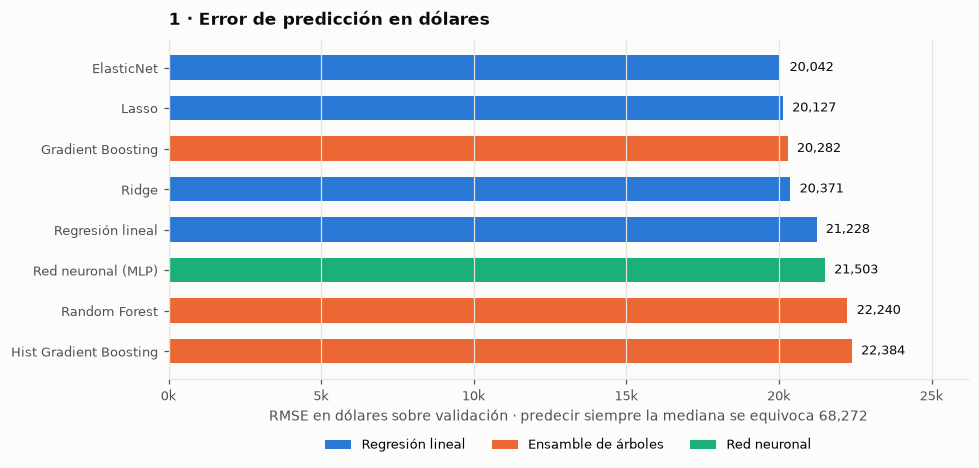

In [11]:
# Handles para la leyenda de familias, reutilizados en varias figuras.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

FAMILIAS_PRESENTES = list(dict.fromkeys(torneo["familia"]))
LEYENDA_FAMILIAS = [Patch(facecolor=COLOR_FAMILIA[f], label=f) for f in FAMILIAS_PRESENTES]

# Nombres cortos, solo para las figuras donde la etiqueta va pegada a un punto.
ABREVIATURA = {
    "Hist Gradient Boosting": "Hist GB",
    "Gradient Boosting": "Grad. Boosting",
    "Red neuronal (MLP)": "MLP",
    "Regresión lineal": "OLS",
}


def color_de(modelo):
    return COLOR_FAMILIA[torneo.loc[modelo, "familia"]]


def leyenda_abajo(ax, handles=None, ncols=3):
    """Leyenda bajo el eje: dentro del área de dibujo tapaba las barras."""
    ax.legend(handles=handles or LEYENDA_FAMILIAS, loc="upper center",
              bbox_to_anchor=(0.5, -0.14), ncols=ncols, frameon=False)


# --- Figura 1: cuánto se equivoca cada modelo, en dólares -------------------------
# Barras horizontales: 8 categorías con nombres largos no caben en un eje vertical.
orden = tabla.sort_values("rmse_real_val", ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.4))
barras = ax.barh(orden.index, orden["rmse_real_val"],
                 color=[color_de(m) for m in orden.index], height=0.6)
ax.bar_label(barras, labels=[f"{v:,.0f}" for v in orden["rmse_real_val"]],
             padding=6, color=TINTA, fontsize=8.5)

ax.set_xlim(0, orden["rmse_real_val"].max() * 1.17)
# El predictor trivial (68 mil) queda tres veces fuera de este eje; dibujarlo aplastaría
# las barras, así que su cifra va en la etiqueta y no como línea.
ax.set_xlabel(f"RMSE en dólares sobre validación · predecir siempre la mediana "
              f"se equivoca {base['rmse_real']:,.0f}")
ax.set_title("1 · Error de predicción en dólares")
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(miles))
ax.grid(axis="y", visible=False)
leyenda_abajo(ax)
plt.tight_layout()
FIGURAS["01_error_en_dolares"] = fig
plt.show()

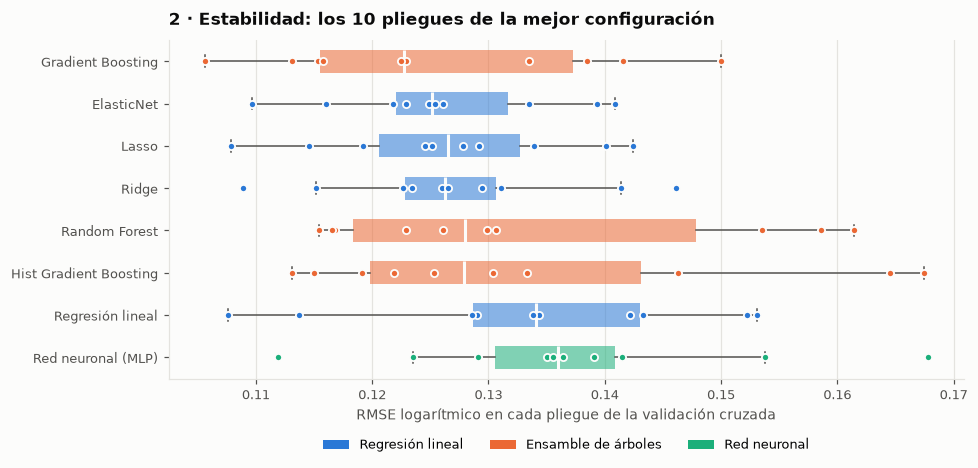

desviación del RMSE logarítmico entre pliegues (menor = más estable):
modelo
ElasticNet                0.0092
Lasso                     0.0102
Ridge                     0.0105
Gradient Boosting         0.0136
Regresión lineal          0.0142
Red neuronal (MLP)        0.0146
Random Forest             0.0170
Hist Gradient Boosting    0.0186


In [12]:
# --- Figura 2: estabilidad entre los 10 pliegues ----------------------------------
# La media de la tabla esconde la dispersión; aquí se ven los diez valores.
orden2 = tabla.sort_values("rmse_log_cv", ascending=False).index

fig, ax = plt.subplots(figsize=(9, 4.4))
datos = [pliegues[m] for m in orden2]
caja = ax.boxplot(datos, orientation="horizontal", widths=0.55, patch_artist=True,
                  tick_labels=list(orden2), showfliers=False,
                  medianprops={"color": SUPERFICIE, "linewidth": 2},
                  whiskerprops={"color": TINTA_SUAVE, "linewidth": 1},
                  capprops={"color": TINTA_SUAVE, "linewidth": 1},
                  boxprops={"linewidth": 0})
for parche, modelo in zip(caja["boxes"], orden2):
    parche.set_facecolor(color_de(modelo))
    parche.set_alpha(0.55)

# Los diez pliegues, uno a uno, con un anillo del color del fondo para que no se peguen.
for i, modelo in enumerate(orden2, start=1):
    ax.scatter(pliegues[modelo], np.full(K_PLIEGUES, i), s=22,
               color=color_de(modelo), edgecolor=SUPERFICIE, linewidth=1.2, zorder=3)

ax.set_xlabel("RMSE logarítmico en cada pliegue de la validación cruzada")
ax.set_title("2 · Estabilidad: los 10 pliegues de la mejor configuración")
ax.grid(axis="y", visible=False)
leyenda_abajo(ax)
plt.tight_layout()
FIGURAS["02_estabilidad_pliegues"] = fig
plt.show()

print("desviación del RMSE logarítmico entre pliegues (menor = más estable):")
print(torneo["rmse_log_cv_sd"].sort_values().round(4).to_string())

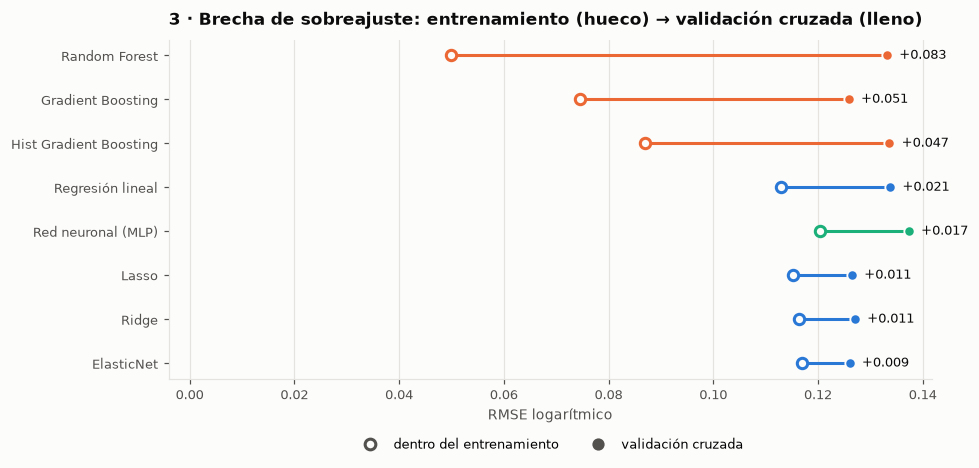

In [13]:
# --- Figura 3: memoriza o generaliza ----------------------------------------------
# Un segmento por modelo: de su error dentro del entrenamiento a su error en
# validación cruzada. Cuanto más largo, más memorizó.
brechas = (torneo["rmse_log_cv"] - torneo["rmse_log_entrena"]).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.4))
for i, modelo in enumerate(brechas.index):
    x0 = torneo.loc[modelo, "rmse_log_entrena"]
    x1 = torneo.loc[modelo, "rmse_log_cv"]
    ax.plot([x0, x1], [i, i], color=color_de(modelo), linewidth=2, zorder=2)
    ax.scatter([x0], [i], s=46, facecolor=SUPERFICIE, edgecolor=color_de(modelo),
               linewidth=2, zorder=3)
    ax.scatter([x1], [i], s=46, color=color_de(modelo), edgecolor=SUPERFICIE,
               linewidth=1.2, zorder=3)
    ax.annotate(f"{x1 - x0:+.3f}", xy=(x1, i), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=TINTA)

ax.set_yticks(range(len(brechas)), list(brechas.index))
ax.set_xlim(left=-0.004)
ax.set_xlabel("RMSE logarítmico")
ax.set_title("3 · Brecha de sobreajuste: entrenamiento (hueco) → validación cruzada (lleno)")
ax.grid(axis="y", visible=False)
leyenda_abajo(ax, handles=[
    Line2D([], [], marker="o", linestyle="", markerfacecolor=SUPERFICIE,
           markeredgecolor=TINTA_SUAVE, markeredgewidth=2, markersize=7,
           label="dentro del entrenamiento"),
    Line2D([], [], marker="o", linestyle="", color=TINTA_SUAVE, markersize=7,
           label="validación cruzada"),
], ncols=2)
plt.tight_layout()
FIGURAS["03_brecha_sobreajuste"] = fig
plt.show()

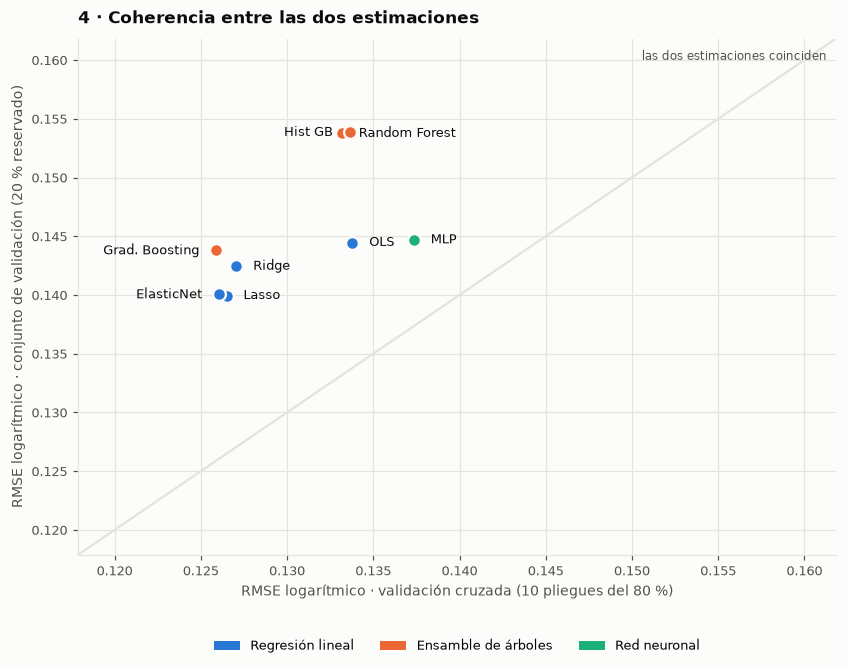

In [14]:
# --- Figura 4: ¿se puede confiar en la validación cruzada? ------------------------
# Si la estimación de 10 pliegues fuese perfecta, cada modelo caería sobre la
# diagonal. Por encima: el 20 % reservado le salió más difícil que los pliegues.
fig, ax = plt.subplots(figsize=(7.8, 6.2))

limites = [min(torneo["rmse_log_cv"].min(), torneo["rmse_log_val"].min()) - 0.008,
           max(torneo["rmse_log_cv"].max(), torneo["rmse_log_val"].max()) + 0.008]
ax.plot(limites, limites, color=REJILLA, linewidth=1.5, zorder=1)
ax.annotate("las dos estimaciones coinciden", xy=(limites[1], limites[1]), xytext=(-6, -14),
            textcoords="offset points", ha="right", fontsize=8, color=TINTA_SUAVE)

# Varios modelos caen casi en el mismo punto (ElasticNet y Lasso se superponen). Las
# etiquetas se escriben a la derecha por defecto y solo cambian de lado cuando el punto
# anterior en orden vertical está además cerca en horizontal: alternar siempre hacía que
# dos puntos lejanos se escribieran uno hacia el otro y chocaran en el medio.
CERCANIA = 0.002
lado, previo = {}, None
for modelo in torneo["rmse_log_val"].sort_values().index:
    distancia_x = (abs(torneo.loc[modelo, "rmse_log_cv"] - torneo.loc[previo, "rmse_log_cv"])
                   if previo else np.inf)
    lado[modelo] = -lado[previo] if distancia_x < CERCANIA else 1
    previo = modelo

for modelo in torneo.index:
    x, y_ = torneo.loc[modelo, "rmse_log_cv"], torneo.loc[modelo, "rmse_log_val"]
    ax.scatter([x], [y_], s=70, color=color_de(modelo), edgecolor=SUPERFICIE,
               linewidth=1.5, zorder=3)
    ax.annotate(ABREVIATURA.get(modelo, modelo), xy=(x, y_),
                xytext=(11 * lado[modelo], 0), textcoords="offset points",
                ha="left" if lado[modelo] > 0 else "right", va="center",
                fontsize=8.5, color=TINTA)

ax.set_xlim(*limites)
ax.set_ylim(*limites)
ax.set_xlabel("RMSE logarítmico · validación cruzada (10 pliegues del 80 %)")
ax.set_ylabel("RMSE logarítmico · conjunto de validación (20 % reservado)")
ax.set_title("4 · Coherencia entre las dos estimaciones")
leyenda_abajo(ax)
plt.tight_layout()
FIGURAS["04_coherencia_cv_validacion"] = fig
plt.show()

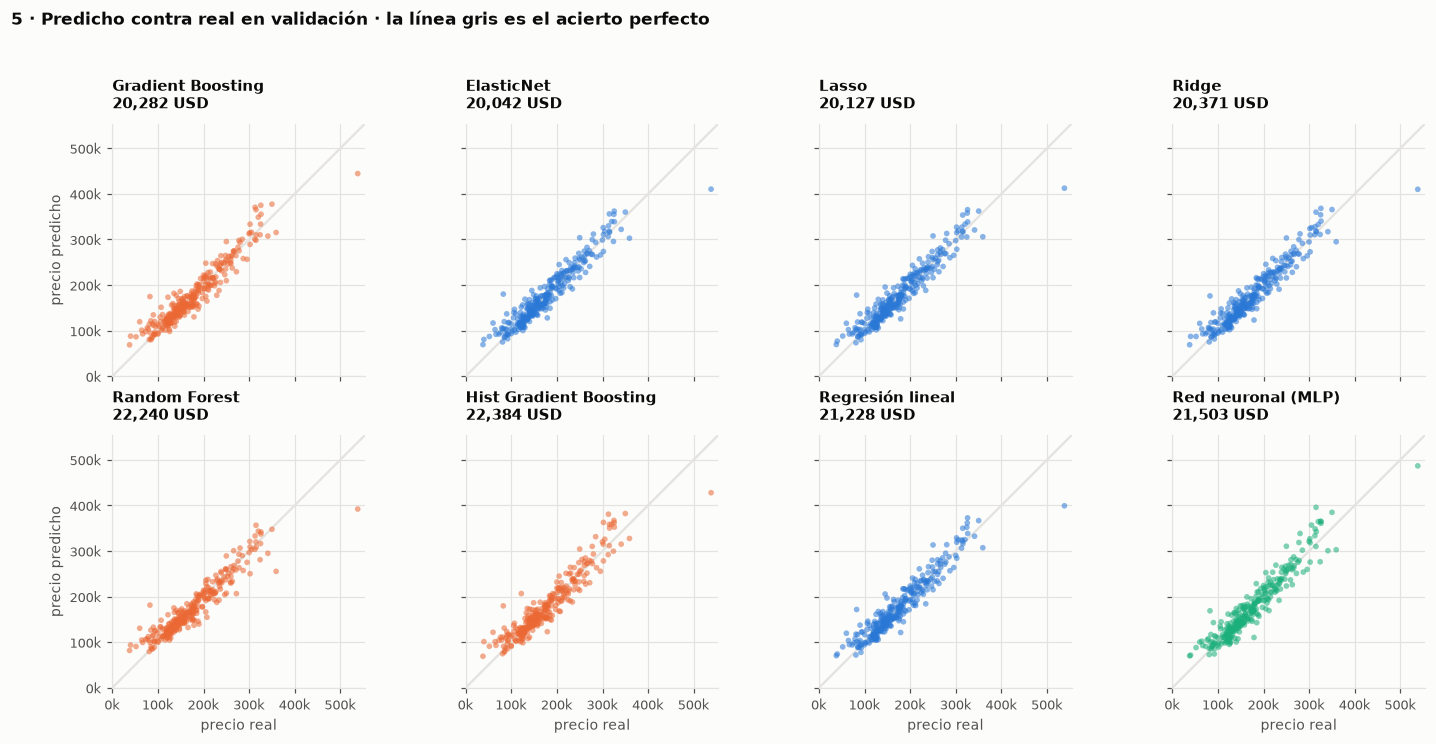

In [15]:
# --- Figura 5: predicho contra real, un panel por modelo --------------------------
# Todo en dólares y con ejes compartidos, para que los paneles se comparen entre sí.
modelos_orden = list(tabla.index)       # del mejor al peor
fig, ejes = plt.subplots(2, 4, figsize=(13.5, 6.8), sharex=True, sharey=True)

tope = float(max(y_valida_real.max(), max(np.expm1(p).max() for p in predicciones.values())))
rango_ejes = [0, tope * 1.03]

for ax, modelo in zip(ejes.flat, modelos_orden):
    real = y_valida_real
    predicho = np.expm1(predicciones[modelo])
    ax.plot(rango_ejes, rango_ejes, color=REJILLA, linewidth=1.5, zorder=1)
    ax.scatter(real, predicho, s=14, color=color_de(modelo), alpha=0.55,
               edgecolor="none", zorder=2)
    ax.set_title(f"{modelo}\n{torneo.loc[modelo, 'rmse_real_val']:,.0f} USD", fontsize=9.5)
    ax.set_xlim(*rango_ejes)
    ax.set_ylim(*rango_ejes)
    ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(miles))
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(miles))
    ax.set_aspect("equal")

for ax in ejes[1]:
    ax.set_xlabel("precio real")
for ax in ejes[:, 0]:
    ax.set_ylabel("precio predicho")

fig.suptitle("5 · Predicho contra real en validación · la línea gris es el acierto perfecto",
             x=0.011, ha="left", fontsize=11, fontweight="bold", color=TINTA)
plt.tight_layout(rect=(0, 0, 1, 0.95))
FIGURAS["05_predicho_contra_real"] = fig
plt.show()

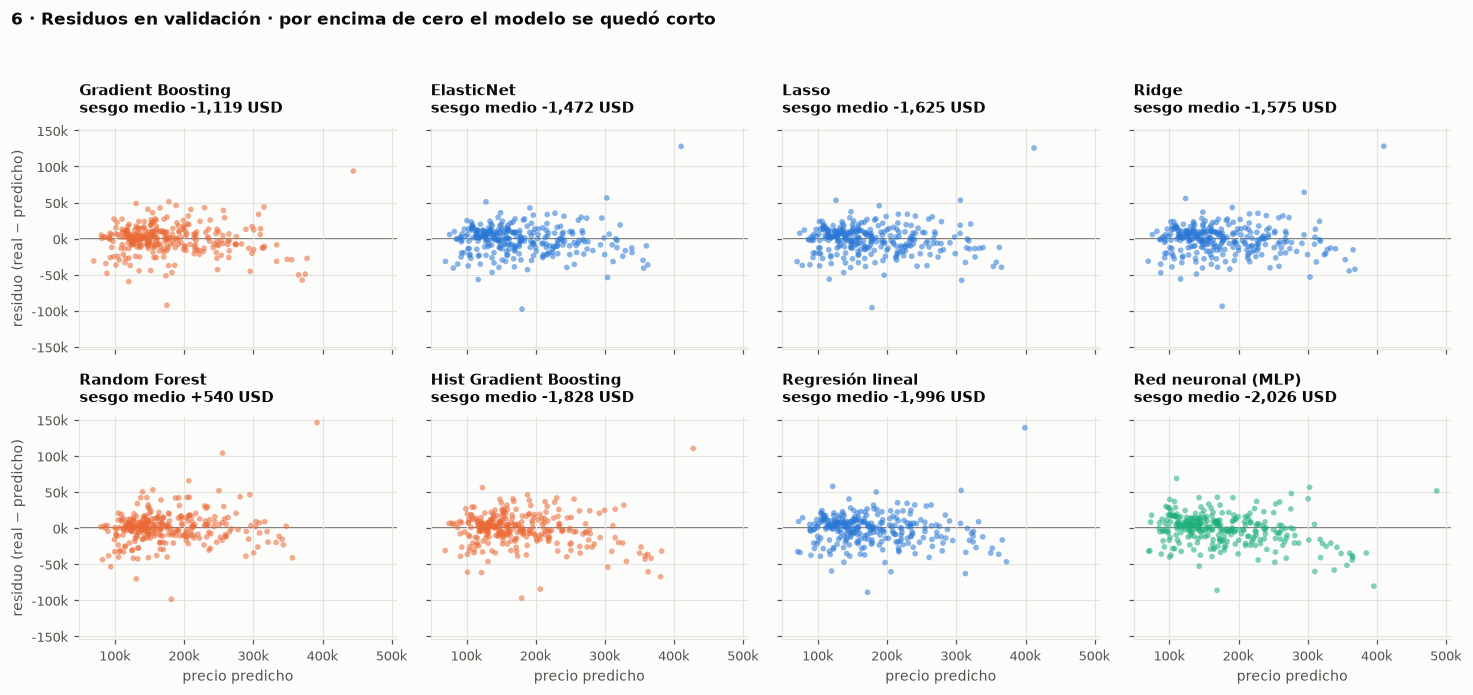

In [16]:
# --- Figura 6: estructura de los residuos -----------------------------------------
# Residuo = real - predicho, en dólares, contra el precio predicho. Una nube
# centrada en cero y sin forma significa que no quedó señal sin aprovechar.
fig, ejes = plt.subplots(2, 4, figsize=(13.5, 6.4), sharex=True, sharey=True)

residuos = {m: y_valida_real - np.expm1(p) for m, p in predicciones.items()}
tope_res = float(max(np.abs(r).max() for r in residuos.values())) * 1.05

for ax, modelo in zip(ejes.flat, modelos_orden):
    predicho = np.expm1(predicciones[modelo])
    ax.axhline(0, color=TINTA_SUAVE, linewidth=1, zorder=1)
    ax.scatter(predicho, residuos[modelo], s=14, color=color_de(modelo), alpha=0.55,
               edgecolor="none", zorder=2)
    sesgo = float(np.mean(residuos[modelo]))
    ax.set_title(f"{modelo}\nsesgo medio {sesgo:+,.0f} USD", fontsize=9.5)
    ax.set_ylim(-tope_res, tope_res)
    ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(miles))
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(miles))

for ax in ejes[1]:
    ax.set_xlabel("precio predicho")
for ax in ejes[:, 0]:
    ax.set_ylabel("residuo (real − predicho)")

fig.suptitle("6 · Residuos en validación · por encima de cero el modelo se quedó corto",
             x=0.011, ha="left", fontsize=11, fontweight="bold", color=TINTA)
plt.tight_layout(rect=(0, 0, 1, 0.95))
FIGURAS["06_residuos"] = fig
plt.show()

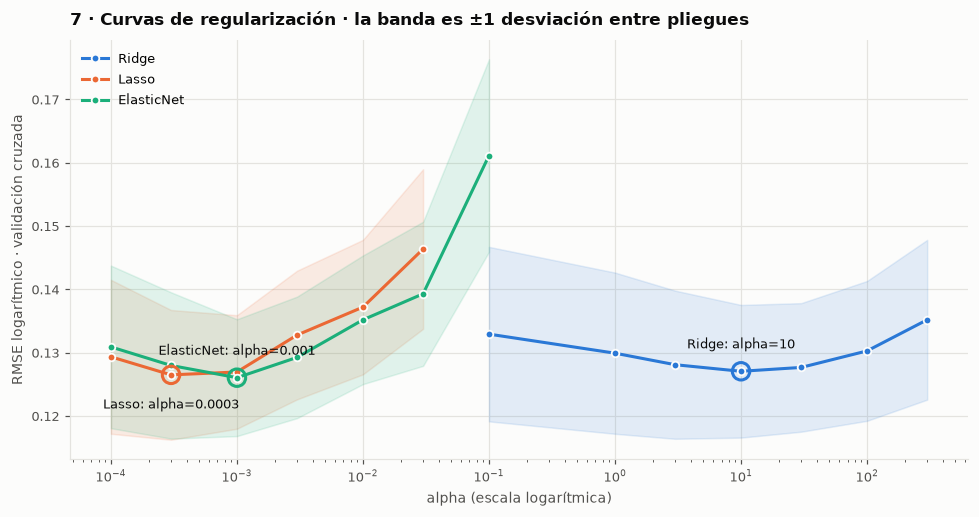

¿quedó el óptimo en un extremo de la rejilla?
  Ridge        alpha=10       rejilla [0.1, 300]  no
  Lasso        alpha=0.0003   rejilla [0.0001, 0.03]  no
  ElasticNet   alpha=0.001    rejilla [0.0001, 0.1]  no


In [17]:
# --- Figura 7: ¿quedó el óptimo de regularización dentro de la rejilla? -----------
# Si el mejor alpha cae en un extremo del barrido, la rejilla era demasiado corta
# y hay que ampliarla. Solo aplica a los tres modelos lineales regularizados.
def curva_hiperparametro(modelo, parametro):
    """Corte 1-D de cv_results_: varía un parámetro y fija los demás en su mejor valor."""
    res = pd.DataFrame(busquedas[modelo].cv_results_)
    mascara = pd.Series(True, index=res.index)
    for clave, valor in busquedas[modelo].best_params_.items():
        if clave != f"modelo__{parametro}":
            mascara &= res[f"param_{clave}"] == valor
    corte = res.loc[mascara].copy()
    corte["valor"] = corte[f"param_modelo__{parametro}"].astype(float)
    corte["rmse_log"] = -corte["mean_test_rmse_log"]
    corte["sd"] = corte["std_test_rmse_log"]
    return corte.sort_values("valor")


REGULARIZADOS = ["Ridge", "Lasso", "ElasticNet"]
# Lasso y ElasticNet tienen su óptimo casi en el mismo sitio: sus etiquetas se separan
# a mano, una arriba y otra abajo.
DESPLAZAMIENTO = {"Ridge": 15, "Lasso": -22, "ElasticNet": 15}

fig, ax = plt.subplots(figsize=(9, 4.8))

for modelo, color in zip(REGULARIZADOS, ["#2a78d6", "#eb6834", "#1baf7a"]):
    curva = curva_hiperparametro(modelo, "alpha")
    ax.plot(curva["valor"], curva["rmse_log"], color=color, marker="o", markersize=5,
            markeredgecolor=SUPERFICIE, markeredgewidth=1.2, label=modelo, zorder=3)
    ax.fill_between(curva["valor"], curva["rmse_log"] - curva["sd"],
                    curva["rmse_log"] + curva["sd"], color=color, alpha=0.12, zorder=2)
    # El alpha elegido, con etiqueta directa: un solo número por serie, no uno por punto.
    mejor_alpha = float(busquedas[modelo].best_params_["modelo__alpha"])
    mejor_rmse = float(curva.loc[curva["valor"] == mejor_alpha, "rmse_log"].iloc[0])
    ax.scatter([mejor_alpha], [mejor_rmse], s=130, facecolor="none", edgecolor=color,
               linewidth=2, zorder=4)
    ax.annotate(f"{modelo}: alpha={mejor_alpha:g}", xy=(mejor_alpha, mejor_rmse),
                xytext=(0, DESPLAZAMIENTO[modelo]), textcoords="offset points",
                ha="center", fontsize=8.5, color=TINTA)

ax.set_xscale("log")
ax.set_xlabel("alpha (escala logarítmica)")
ax.set_ylabel("RMSE logarítmico · validación cruzada")
ax.set_title("7 · Curvas de regularización · la banda es ±1 desviación entre pliegues")
ax.legend(loc="upper left")
plt.tight_layout()
FIGURAS["07_curvas_regularizacion"] = fig
plt.show()

print("¿quedó el óptimo en un extremo de la rejilla?")
for modelo in REGULARIZADOS:
    valores = sorted(float(v) for v in CANDIDATOS[modelo]["grid"]["alpha"])
    elegido = float(busquedas[modelo].best_params_["modelo__alpha"])
    borde = "SÍ — conviene ampliar la rejilla" if elegido in (valores[0], valores[-1]) else "no"
    print(f"  {modelo:12} alpha={elegido:<8g} rejilla [{valores[0]:g}, {valores[-1]:g}]  {borde}")

## 9. El ganador bajo la lupa

Dos diagnósticos más, solo para el modelo que ganó el torneo.

**La curva de aprendizaje** entrena el mismo modelo con fracciones crecientes del conjunto de
entrenamiento y mide, en cada tamaño, el error dentro del entrenamiento y el de validación
cruzada. La forma de las dos curvas dice qué limita al modelo:

| Forma | Diagnóstico | Qué hacer |
|---|---|---|
| Las curvas siguen separadas al final | Sobreajuste: el modelo tiene más capacidad que datos | Más datos, o más regularización |
| Convergen, pero alto | Subajuste: el modelo es demasiado simple para la señal | Más capacidad, o mejores features |
| Convergen bajo y planas | Bien dimensionado | Nada; el techo está en los datos |

Si la curva de validación cruzada todavía baja en el extremo derecho, más datos ayudarían. Si
ya está plana, el límite son las features y no el tamaño de la muestra.

Una advertencia técnica sobre esta curva: entrenar con 157 filas destapa una fragilidad del
pipeline guardado —su imputador de moda aborta cuando dos categorías de `Neighborhood` empatan
como la más frecuente— y `learning_curve` traduce ese fallo a un `NaN` sin decir nada. La celda
lo resuelve retirando ese paso del clon que usa la curva, después de **probar con un `assert`**
que las columnas afectadas no tienen ni un faltante y que el paso, por tanto, no cambia ningún
valor. El pipeline del torneo no se toca.

**La importancia por permutación** mide cuánto empeora el RMSE al barajar al azar una columna
del conjunto de validación, dejando todo lo demás intacto. Si barajarla no cambia nada, el
modelo no la estaba usando.

Tiene dos virtudes aquí. La primera es que se calcula **sobre validación**, no sobre
entrenamiento: mide la contribución a predecir datos nuevos, no a memorizar los viejos. La
segunda es consecuencia de la arquitectura de la sección 3: como el pipeline recibe las 30
columnas crudas, la permutación ocurre **antes** del one-hot, así que `Neighborhood` se evalúa
como una sola variable y no como 25 dummies que se diluyen entre sí.

paso 'moda_hasta_5' retirado solo para esta curva (10 columnas, 0 faltantes) · quedan 12 pasos
curva de aprendizaje de ElasticNet...


listo en 14.4 s


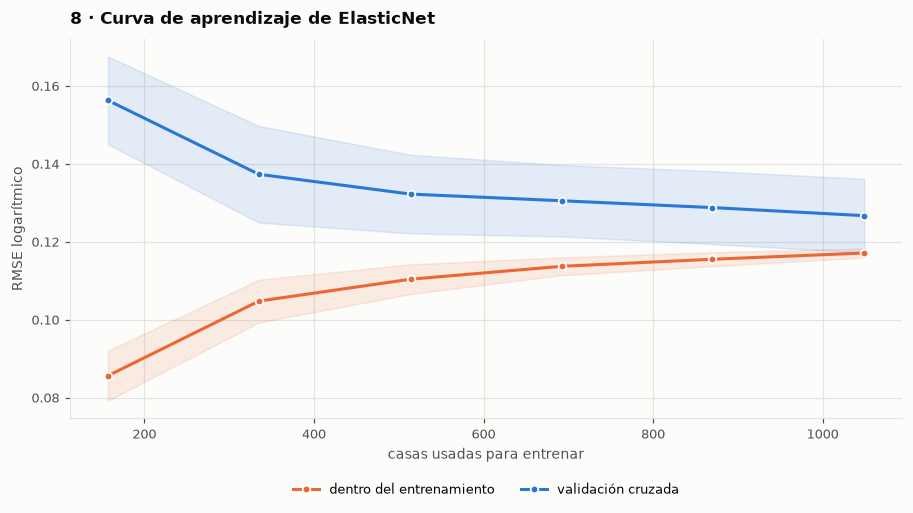


brecha final entre las dos curvas: 0.0096
mejora de la curva de validación en el último tramo: +0.0021
(si sigue bajando, más datos ayudarían; si es ~0, el techo está en las features)


In [18]:
# --- Figura 8: curva de aprendizaje del ganador -----------------------------------
# Un tropiezo del pipeline en muestras pequeñas, y por qué se resuelve quitando un paso:
#
# `CategoricalImputer(imputation_method="frequent")` lanza un error si dos categorías
# empatan como la más frecuente, y con 157 filas `Neighborhood` empata a menudo. Como
# `learning_curve` convierte cualquier fallo de ajuste en un NaN silencioso, el primer
# punto de la curva salía vacío sin avisar.
#
# La solución no es parchear el imputador: en estos datos ese paso es un no-op
# verificable —ninguna de sus diez columnas tiene faltantes en entrenamiento— y solo
# está en el pipeline como seguro para los faltantes que sí trae el test de Kaggle.
# Se quita del clon que usa la curva, y el assert de abajo prueba que quitarlo no
# cambia ningún valor imputado. El pipeline del torneo queda intacto.
modelo_curva = clone(busquedas[GANADOR].best_estimator_)
pasos_curva = modelo_curva.named_steps["features"].steps
posicion = [i for i, (nombre, _) in enumerate(pasos_curva) if nombre == "moda_hasta_5"][0]
columnas_moda = pasos_curva[posicion][1].variables

assert X_entrena[columnas_moda].isna().sum().sum() == 0, \
    "esas columnas sí tienen faltantes: quitar el paso cambiaría el resultado"
pasos_curva.pop(posicion)

print(f"paso 'moda_hasta_5' retirado solo para esta curva "
      f"({len(columnas_moda)} columnas, 0 faltantes) · quedan {len(pasos_curva)} pasos")
print(f"curva de aprendizaje de {GANADOR}...")
inicio = time.perf_counter()

tamanos, error_entrena, error_cv = learning_curve(
    modelo_curva,
    X_entrena, y_entrena,
    train_sizes=np.linspace(0.15, 1.0, 6),
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=N_JOBS,
    shuffle=True,
    random_state=SEMILLA,
    error_score="raise",     # que un fallo se vea, en vez de volverse NaN
)
error_entrena, error_cv = -error_entrena, -error_cv
assert not (np.isnan(error_entrena).any() or np.isnan(error_cv).any()), "la curva trae NaN"
print(f"listo en {time.perf_counter() - inicio:.1f} s")

fig, ax = plt.subplots(figsize=(8.4, 4.8))
for datos, color, etiqueta in [
    (error_entrena, "#eb6834", "dentro del entrenamiento"),
    (error_cv, "#2a78d6", "validación cruzada"),
]:
    media, sd = datos.mean(axis=1), datos.std(axis=1)
    ax.plot(tamanos, media, color=color, marker="o", markersize=5,
            markeredgecolor=SUPERFICIE, markeredgewidth=1.2, label=etiqueta, zorder=3)
    ax.fill_between(tamanos, media - sd, media + sd, color=color, alpha=0.12, zorder=2)

ax.set_xlabel("casas usadas para entrenar")
ax.set_ylabel("RMSE logarítmico")
ax.set_title(f"8 · Curva de aprendizaje de {GANADOR}")
leyenda_abajo(ax, handles=ax.get_legend_handles_labels()[0], ncols=2)
plt.tight_layout()
FIGURAS["08_curva_aprendizaje"] = fig
plt.show()

print(f"\nbrecha final entre las dos curvas: {error_cv.mean(axis=1)[-1] - error_entrena.mean(axis=1)[-1]:.4f}")
print(f"mejora de la curva de validación en el último tramo: "
      f"{error_cv.mean(axis=1)[-2] - error_cv.mean(axis=1)[-1]:+.4f}")
print("(si sigue bajando, más datos ayudarían; si es ~0, el techo está en las features)")

importancia por permutación de ElasticNet (30 variables × 10 repeticiones)...


listo en 91.3 s


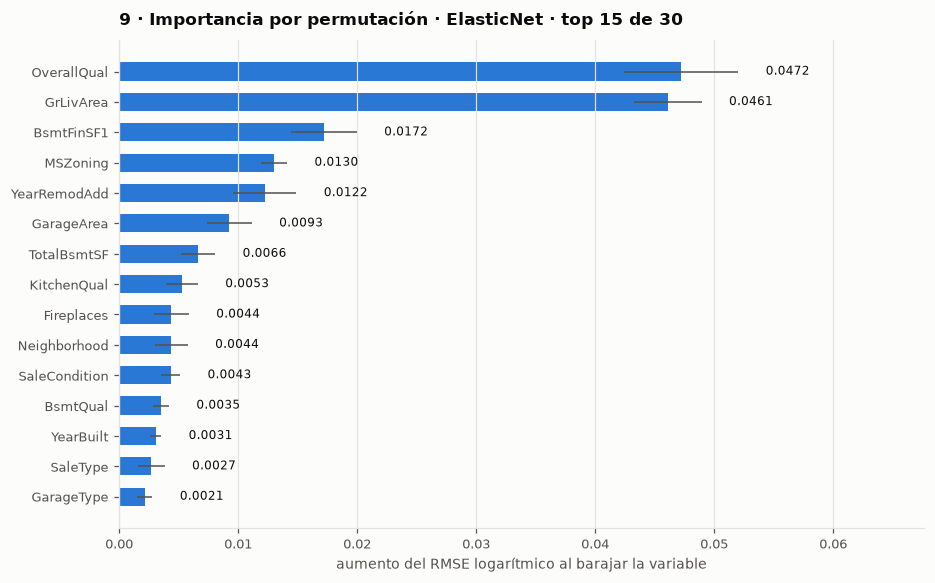


variables que el modelo no usa (barajarlas no empeora nada): 3 de 30
  FullBath, FireplaceQu, Exterior2nd

las 5 más importantes concentran 70% de la importancia total


In [19]:
# --- Figura 9: importancia por permutación del ganador ----------------------------
# Se mide sobre validación y sobre las 30 columnas CRUDAS, antes del one-hot.
print(f"importancia por permutación de {GANADOR} (30 variables × 10 repeticiones)...")
inicio = time.perf_counter()

importancia = permutation_importance(
    busquedas[GANADOR].best_estimator_,
    X_valida, y_valida,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=SEMILLA,
    n_jobs=1,
)
print(f"listo en {time.perf_counter() - inicio:.1f} s")

imp = pd.DataFrame({
    "variable": X_valida.columns,
    "media": importancia.importances_mean,
    "sd": importancia.importances_std,
}).sort_values("media", ascending=False)

TOP = 15
arriba = imp.head(TOP).iloc[::-1]       # invertido: la más importante arriba en barh

fig, ax = plt.subplots(figsize=(8.6, 5.4))
barras = ax.barh(arriba["variable"], arriba["media"], height=0.6,
                 color=color_de(GANADOR), xerr=arriba["sd"],
                 error_kw={"ecolor": TINTA_SUAVE, "elinewidth": 1, "capsize": 0})
ax.bar_label(barras, labels=[f"{v:.4f}" for v in arriba["media"]], padding=18,
             color=TINTA, fontsize=8)
ax.set_xlim(0, (arriba["media"] + arriba["sd"]).max() * 1.3)
ax.set_xlabel("aumento del RMSE logarítmico al barajar la variable")
ax.set_title(f"9 · Importancia por permutación · {GANADOR} · top {TOP} de 30")
ax.grid(axis="y", visible=False)
plt.tight_layout()
FIGURAS["09_importancia_permutacion"] = fig
plt.show()

sin_uso = imp[imp["media"] <= 0]
print(f"\nvariables que el modelo no usa (barajarlas no empeora nada): {len(sin_uso)} de 30")
if len(sin_uso):
    print("  " + ", ".join(sin_uso["variable"]))
print(f"\nlas 5 más importantes concentran "
      f"{imp.head(5)['media'].sum() / imp['media'].clip(lower=0).sum():.0%} de la importancia total")

## 10. Guardado — el modelo del torneo

- **`models/modelo_ganador.joblib`** — el pipeline completo del ganador: las 13
  transformaciones más el modelo, ajustados sobre el **80 %** de entrenamiento. Recibe las 30
  columnas crudas y devuelve predicciones en logaritmo, así que quien lo use debe aplicar
  `expm1` para volver a dólares. Se guarda junto con sus métricas para que el número no se
  despegue del objeto que lo produjo.

- **`reports/torneo_modelos.csv`** — la tabla de la sección 7.

**Este artefacto se queda con el 80 % a propósito.** Es el objeto que produjo el RMSE de
validación de este notebook; si se reajustara con todas las filas, la cifra dejaría de ser
comprobable contra el modelo que la generó. El modelo para predecir de verdad se construye en
la sección siguiente, en un archivo aparte.

In [20]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

ruta_modelo = MODELS_DIR / "modelo_ganador.joblib"
ruta_tabla = REPORTS_DIR / "torneo_modelos.csv"

joblib.dump(
    {
        "nombre": GANADOR,
        "pipeline": busquedas[GANADOR].best_estimator_,
        "mejor_config": torneo.loc[GANADOR, "mejor_config"],
        "features": FEATURES,
        "target": "log1p(SalePrice)",
        "ajustado_con": f"{len(X_entrena)} filas (80 % de train)",
        "metricas_validacion": {
            "rmse_log": float(torneo.loc[GANADOR, "rmse_log_val"]),
            "rmse_real": float(torneo.loc[GANADOR, "rmse_real_val"]),
            "nrmse_rango": float(torneo.loc[GANADOR, "nrmse_rango_val"]),
        },
        "rmse_log_cv": float(torneo.loc[GANADOR, "rmse_log_cv"]),
        "semilla": SEMILLA,
    },
    ruta_modelo,
)
tabla.to_csv(ruta_tabla, encoding="utf-8")

# Comprobación: el modelo recargado predice exactamente lo mismo.
recargado = joblib.load(ruta_modelo)
assert np.allclose(recargado["pipeline"].predict(X_valida), predicciones[GANADOR]), \
    "el modelo recargado no reproduce las predicciones"

print(f"{ruta_modelo.relative_to(RAIZ)}  ({ruta_modelo.stat().st_size / 1024:,.0f} KB)")
print(f"{ruta_tabla.relative_to(RAIZ)}")
print("\nel modelo recargado reproduce las predicciones ✓")
print(f"\nganador: {GANADOR} · {torneo.loc[GANADOR, 'mejor_config']}")
print(f"rmse_log {torneo.loc[GANADOR, 'rmse_log_val']:.4f} · "
      f"rmse_real {torneo.loc[GANADOR, 'rmse_real_val']:,.0f} USD · "
      f"nrmse {torneo.loc[GANADOR, 'nrmse_rango_val']:.2%} del rango")

models\modelo_ganador.joblib  (44 KB)
reports\torneo_modelos.csv

el modelo recargado reproduce las predicciones ✓

ganador: ElasticNet · alpha=0.001, l1_ratio=0.5
rmse_log 0.1401 · rmse_real 20,042 USD · nrmse 4.01% del rango


## 10.1 El modelo de producción

El modelo con el que se va a predecir de verdad no es el mismo objeto que compitió en el
torneo. Es **la misma receta reajustada con las 1458 filas**: misma familia, misma
configuración de hiperparámetros, mismos 13 pasos de ingeniería de características, pero
entrenado con un 25 % más de casas.

**Por qué se reentrena.** Las 292 filas que se reservaron para validar ya cumplieron su
función —dar una estimación honesta del error— y no hay razón para seguir desperdiciándolas.
Un modelo que ve 1458 ejemplos aprende algo más que uno que ve 1166, sobre todo en los
extremos del rango de precios, que son los que peor se predicen y los que menos casos tienen.
Los hiperparámetros no se vuelven a buscar: se heredan tal cual del torneo, porque buscarlos
otra vez sobre los datos completos usaría las filas de validación para elegir y reabriría la
puerta que todo el notebook mantuvo cerrada.

**Por qué va en otro archivo.** `modelo_ganador.joblib` es evidencia: es el objeto exacto que
produjo los 20 042 dólares de la sección 7, y mientras exista esa cifra se puede volver a
comprobar. `modelo_produccion.joblib` es la herramienta. Mezclarlos obligaría a elegir entre
tener un número verificable o tener el mejor modelo posible, y no hace falta elegir.

**Una advertencia que viaja con el archivo.** El modelo de producción **ya vio** las 292 filas
de validación, así que medirlo contra ellas daría una cifra optimista y sin sentido. Su error
esperado es el del modelo hermano —RMSE logarítmico ≈ 0.14, unos 20 mil dólares— quizá un poco
mejor por los datos extra. Esa advertencia se guarda dentro del propio artefacto, en el campo
`advertencia`, para que nadie la reconstruya mal más adelante.

In [21]:
# Misma receta, más datos: se clona el ganador (configuración sin ajustar) y se
# reajusta con las 1458 filas. Los hiperparámetros se heredan, no se vuelven a buscar.
modelo_produccion = clone(busquedas[GANADOR].best_estimator_)
modelo_produccion.fit(X, y)

ruta_produccion = MODELS_DIR / "modelo_produccion.joblib"

joblib.dump(
    {
        "nombre": GANADOR,
        "pipeline": modelo_produccion,
        "mejor_config": torneo.loc[GANADOR, "mejor_config"],
        "features": FEATURES,
        "entrada": "las 30 columnas crudas de data/raw, sin transformar",
        "salida": "log1p(SalePrice) · aplicar np.expm1 para volver a dólares",
        "ajustado_con": f"{len(X)} filas (train completo, sin los outliers 524 y 1299)",
        "error_esperado": {
            "rmse_log": float(torneo.loc[GANADOR, "rmse_log_val"]),
            "rmse_real": float(torneo.loc[GANADOR, "rmse_real_val"]),
            "nrmse_rango": float(torneo.loc[GANADOR, "nrmse_rango_val"]),
        },
        "advertencia": (
            "Estas métricas son las del modelo hermano modelo_ganador.joblib, ajustado "
            "solo con el 80 %. Este modelo ya vio las filas de validación: medirlo contra "
            "ellas daría una cifra optimista y sin significado."
        ),
        "semilla": SEMILLA,
    },
    ruta_produccion,
)

# Verificación 1: es el mismo pipeline de 13 pasos, ajustado con todas las filas.
assert len(modelo_produccion.named_steps["features"].steps) == 13, "faltan pasos de features"
assert len(modelo_produccion.predict(X)) == len(X), "no predice sobre todas las filas"

# Verificación 2: el artefacto recargado funciona desde cero.
produccion_recargado = joblib.load(ruta_produccion)["pipeline"]
assert np.allclose(produccion_recargado.predict(X), modelo_produccion.predict(X)), \
    "el modelo de producción recargado no reproduce sus predicciones"

# Cuánto movió el reentrenamiento las predicciones. NO es una evaluación: este modelo
# ya vio estas filas. Solo mide si 292 casas más cambian mucho lo que el modelo dice.
movimiento = np.abs(
    np.expm1(modelo_produccion.predict(X_valida)) - np.expm1(predicciones[GANADOR])
)

print(f"{ruta_produccion.relative_to(RAIZ)}  "
      f"({ruta_produccion.stat().st_size / 1024:,.0f} KB)")
print(f"\n{GANADOR} · {torneo.loc[GANADOR, 'mejor_config']}")
print(f"ajustado con {len(X)} filas (el del torneo usó {len(X_entrena)})")
print("las 2 verificaciones pasan ✓")
print(f"\nefecto del reentrenamiento sobre las mismas 292 casas:")
print(f"  diferencia media    {movimiento.mean():>8,.0f} USD")
print(f"  diferencia mediana  {np.median(movimiento):>8,.0f} USD")
print(f"  diferencia máxima   {movimiento.max():>8,.0f} USD")
print("(no es una medida de error: el modelo de producción ya vio estas filas)")

models\modelo_produccion.joblib  (38 KB)

ElasticNet · alpha=0.001, l1_ratio=0.5
ajustado con 1458 filas (el del torneo usó 1166)
las 2 verificaciones pasan ✓

efecto del reentrenamiento sobre las mismas 292 casas:
  diferencia media       2,104 USD
  diferencia mediana     1,434 USD
  diferencia máxima     15,610 USD
(no es una medida de error: el modelo de producción ya vio estas filas)


## 11. Registro en MLflow

Hasta aquí, todo lo que se midió vive en la memoria del notebook y en dos archivos `.joblib`.
Esta sección lo deposita en un **registro consultable**: qué se probó, con qué resultado, y
cuál de los modelos manda.

### Por qué SQLite y no el almacén de archivos

MLflow admite guardar los experimentos en una carpeta (`./mlruns`) sin base de datos, y para
registrar métricas eso bastaría. Pero el **Model Registry** —el catálogo de modelos con
versiones y alias, que es justo lo que se necesita para nombrar un champion— **no funciona
sobre archivos**. El intento devuelve *"The filesystem tracking backend is in maintenance mode
and will not receive further updates"*.

Por eso el backend es `sqlite:///mlflow.db`: es el mínimo que habilita el registro, no
necesita levantar ningún servidor y vive en un solo archivo. Para mirarlo:

```
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

### Un detalle de serialización que no es opcional

Esta versión de MLflow serializa los modelos de scikit-learn con **skops** por defecto, un
formato que se niega a guardar clases que no reconoce. Nuestro pipeline lleva transformadores
de feature-engine y la clase propia `RellenarAnioGaraje`, así que falla con *"The sklearn model
could not be serialized in the skops serialization format"*. La solución es pedir
explícitamente `serialization_format="cloudpickle"`.

### La estructura de los runs

| Nivel | Qué contiene |
|---|---|
| **Run padre** `torneo` | Lo que describe al experimento entero: las 9 figuras comparativas, la tabla del torneo, el diseño (pliegues, semilla, tamaño de la partición) y el umbral de la regla de 1 error estándar |
| **8 runs anidados** | Uno por candidato: sus mejores hiperparámetros, sus 9 métricas, su rejilla completa de resultados y su modelo serializado |

Anidarlos no es decorativo: deja los artefactos compartidos en un sitio que les corresponde, en
vez de duplicarlos ocho veces o colgarlos arbitrariamente de un modelo.

### Champion y challengers

Se registran **los tres primeros del podio**, con la **misma regla** que coronó al ganador: de
los modelos empatados dentro de un error estándar del mejor, ordenados por brecha de
sobreajuste. El primero recibe el alias `champion` y los dos siguientes, `challenger_1` y
`challenger_2`.

**Los tres se registran reajustados con el 100 % de los datos**, no con el 80 % que compitió.
La razón es que un challenger existe para poder ascender: si mañana se decide promoverlo, tiene
que estar listo para predecir, no requerir un reentrenamiento primero. Cada versión lleva en
sus etiquetas las métricas de su gemelo del 80 % —las únicas honestas— junto con la advertencia
de que fueron medidas sobre otro objeto.

### El modelo tiene que viajar con su código

`cloudpickle` guarda la clase propia `RellenarAnioGaraje` **por referencia**, no por valor:
dentro del archivo solo queda escrito "esto es `house_pricing.features.RellenarAnioGaraje`".
Al recargarlo, Python intenta importar ese módulo — y si el proceso que carga no tiene el
proyecto en su ruta de búsqueda, falla con `ModuleNotFoundError: No module named
'house_pricing'`.

Esto no se nota desde los notebooks, porque ellos insertan la raíz del proyecto en `sys.path`
en su primera celda. Se nota el día que un servicio arranca en otro directorio, que es
precisamente a donde apunta todo este trabajo. Y el paquete tampoco está instalado en el
entorno: el `-e .` de `requirements.txt` nunca llegó a ejecutarse.

La solución es `code_paths`, que copia el paquete **dentro del artefacto del modelo** y lo
antepone a `sys.path` al cargarlo. Con eso la versión registrada se basta a sí misma:
comprobado cargándola desde un proceso que arranca en otra carpeta y sin el proyecto en la
ruta, donde la versión sin `code_paths` falla y la que lo lleva predice correctamente.

### La firma del modelo

Se declara una **firma** con las columnas y tipos de entrada, convirtiendo los enteros a
`float64` a propósito: en Python un entero no puede representar un faltante, y si el día de
mañana llega una petición con `OverallQual` vacío, una firma de enteros rechazaría la fila
entera. Es la recomendación de la documentación de MLflow y aquí es un caso real, porque el
test trae faltantes en nueve columnas que el entrenamiento no tenía.

In [22]:
mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENTO)
cliente = MlflowClient()

# --- El podio: la misma regla de 1 error estándar que eligió al champion ---
# `empatados` son los modelos dentro de un error estándar del mejor promedio,
# y dentro de ellos manda la menor brecha de sobreajuste.
PODIO = list(empatados.sort_values("brecha").index[:3])
if len(PODIO) < 3:
    # Salvaguarda: si el empate dejara menos de tres, se completa por rmse_log_cv.
    resto = [m for m in tabla.sort_values("rmse_log_cv").index if m not in PODIO]
    PODIO += resto[: 3 - len(PODIO)]

ALIAS = dict(zip(PODIO, ["champion", "challenger_1", "challenger_2"]))
assert PODIO[0] == GANADOR, "el champion debería ser el ganador de la sección 7.1"

print("podio:")
for modelo, alias in ALIAS.items():
    print(f"  {alias:14} {modelo:22} brecha {tabla.loc[modelo, 'brecha']:.4f}")


def ejemplo_de_entrada(datos, n=5):
    """Muestra de entrada con los enteros pasados a float64.

    Un entero de Python no admite faltantes: si la firma declara int y llega una
    fila con un hueco en esa columna, MLflow rechaza la petición completa. Con
    float64 el faltante viaja como NaN y el pipeline lo imputa, que es lo que debe
    pasar. Es la recomendación de la documentación de MLflow.
    """
    muestra = datos.head(n).copy()
    enteras = muestra.select_dtypes(include=["int", "int64", "int32"]).columns
    return muestra.astype({columna: "float64" for columna in enteras})


EJEMPLO = ejemplo_de_entrada(X_valida)
print(f"\nejemplo de entrada: {EJEMPLO.shape} · "
      f"{(EJEMPLO.dtypes == 'float64').sum()} columnas float64, "
      f"{(EJEMPLO.dtypes == 'object').sum() + (EJEMPLO.dtypes == 'str').sum()} de texto")

2026/11/05 20:49:27 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/05 20:49:27 INFO mlflow.store.db.utils: Updating database tables


2026/11/05 20:49:33 INFO mlflow.tracking.fluent: Experiment with name 'house_pricing_torneo' does not exist. Creating a new experiment.


podio:
  champion       ElasticNet             brecha 0.0090
  challenger_1   Ridge                  brecha 0.0107
  challenger_2   Lasso                  brecha 0.0112

ejemplo de entrada: (5, 30) · 15 columnas float64, 15 de texto


In [23]:
# --- Run padre: el experimento entero ---
with mlflow.start_run(run_name="torneo") as run_padre:
    mlflow.set_tags({
        "fase": "modelado",
        "dataset": "house_prices_ames",
        "notebook": "4.0-dg-modelado",
        "criterio_seleccion": "1 error estandar sobre rmse_log_cv, desempate por brecha",
    })
    mlflow.log_params({
        "k_pliegues": K_PLIEGUES,
        "semilla": SEMILLA,
        "proporcion_validacion": PROPORCION_VALIDACION,
        "filas_entrenamiento": len(X_entrena),
        "filas_validacion": len(X_valida),
        "features_entrada": len(FEATURES),
        "columnas_tras_pipeline": cols_entrena.shape[1],
        "candidatos": len(CANDIDATOS),
        "configuraciones_totales": int(torneo["configuraciones"].sum()),
    })
    mlflow.log_metrics({
        "umbral_empate": float(umbral),
        "error_estandar_mejor": float(error_estandar),
        "modelos_empatados": float(len(empatados)),
        "rmse_real_referencia_mediana": float(base["rmse_real"]),
    })

    # Las 9 figuras y las tablas, en el run que describe al conjunto.
    for nombre, figura in FIGURAS.items():
        mlflow.log_figure(figura, f"figuras/{nombre}.png")
    mlflow.log_table(tabla.reset_index(), "tablas/torneo.json")
    mlflow.log_text(tabla.to_string(), "tablas/torneo.txt")

    print(f"run padre: {run_padre.info.run_id}")
    print(f"  {len(FIGURAS)} figuras · tabla del torneo · diseño experimental")

    # --- Un run anidado por candidato ---
    versiones = {}
    for nombre in tabla.index:              # del mejor al peor
        fila = torneo.loc[nombre]
        busqueda = busquedas[nombre]
        alias = ALIAS.get(nombre)

        with mlflow.start_run(run_name=nombre, nested=True):
            mlflow.set_tags({
                "familia": fila["familia"],
                "rol": alias.split("_")[0] if alias else "candidato",
                "alias": alias or "",
            })
            mlflow.log_params({
                clave.replace("modelo__", ""): valor
                for clave, valor in busqueda.best_params_.items()
            } or {"hiperparametros": "ninguno"})
            mlflow.log_param("configuraciones_probadas", fila["configuraciones"])

            mlflow.log_metrics({
                "rmse_log_cv": float(fila["rmse_log_cv"]),
                "rmse_log_cv_sd": float(fila["rmse_log_cv_sd"]),
                "rmse_log_entrena": float(fila["rmse_log_entrena"]),
                "brecha_sobreajuste": float(fila["rmse_log_cv"] - fila["rmse_log_entrena"]),
                "rmse_real_cv": float(fila["rmse_real_cv"]),
                "rmse_log_val": float(fila["rmse_log_val"]),
                "rmse_real_val": float(fila["rmse_real_val"]),
                "nrmse_rango_val": float(fila["nrmse_rango_val"]),
                "segundos_busqueda": float(fila["segundos"]),
            })
            # Los 10 pliegues, uno a uno: en la interfaz se ven como una serie.
            for i, valor in enumerate(pliegues[nombre]):
                mlflow.log_metric("rmse_log_por_pliegue", float(valor), step=i)

            # La rejilla completa, para poder auditar la búsqueda después.
            mlflow.log_text(
                pd.DataFrame(busqueda.cv_results_).to_csv(index=False),
                "busqueda/cv_results.csv",
            )

            # El modelo. Los tres del podio se reajustan con el 100 % y se registran:
            # un challenger tiene que estar listo para ascender sin reentrenarse.
            if alias:
                modelo_registrable = clone(busqueda.best_estimator_).fit(X, y)
                ajustado_con = f"{len(X)} filas (train completo)"
            else:
                modelo_registrable = busqueda.best_estimator_
                ajustado_con = f"{len(X_entrena)} filas (80 %)"
            mlflow.log_param("ajustado_con", ajustado_con)

            firma = mlflow.models.infer_signature(
                EJEMPLO, modelo_registrable.predict(EJEMPLO)
            )
            info = mlflow.sklearn.log_model(
                modelo_registrable,
                name="modelo",
                signature=firma,
                input_example=EJEMPLO,
                serialization_format="cloudpickle",   # skops no traga feature-engine
                # Sin esto el modelo no carga fuera de este proyecto: ver sección 11.
                code_paths=[str(RAIZ / "house_pricing")],
                registered_model_name=MODELO_REGISTRADO if alias else None,
            )
            if alias:
                versiones[nombre] = info.registered_model_version

            marca = f"  <- {alias}" if alias else ""
            print(f"  {nombre:24} rmse_log_cv {fila['rmse_log_cv']:.4f}{marca}")

print(f"\n{len(tabla)} runs anidados · {len(versiones)} modelos registrados")

run padre: ee0427ee6c74493abe5ca590c6eecb0c
  9 figuras · tabla del torneo · diseño experimental


  Gradient Boosting        rmse_log_cv 0.1259


Successfully registered model 'house_pricing'.
Created version '1' of model 'house_pricing'.


  ElasticNet               rmse_log_cv 0.1261  <- champion


Registered model 'house_pricing' already exists. Creating a new version of this model...
Created version '2' of model 'house_pricing'.


  Lasso                    rmse_log_cv 0.1265  <- challenger_2


... (2 outputs left out)

  Random Forest            rmse_log_cv 0.1332


  Hist Gradient Boosting   rmse_log_cv 0.1336


  Regresión lineal         rmse_log_cv 0.1338


  Red neuronal (MLP)       rmse_log_cv 0.1374

8 runs anidados · 3 modelos registrados


In [24]:
# --- Alias y etiquetas sobre las versiones registradas ---
for nombre, version in versiones.items():
    alias = ALIAS[nombre]
    fila = torneo.loc[nombre]

    cliente.set_registered_model_alias(MODELO_REGISTRADO, alias, version)
    cliente.set_model_version_tag(MODELO_REGISTRADO, version, "rol", alias)
    cliente.set_model_version_tag(MODELO_REGISTRADO, version, "familia", fila["familia"])
    cliente.set_model_version_tag(MODELO_REGISTRADO, version, "configuracion",
                                  fila["mejor_config"])
    cliente.set_model_version_tag(MODELO_REGISTRADO, version, "ajustado_con",
                                  f"{len(X)} filas (train completo)")
    cliente.set_model_version_tag(MODELO_REGISTRADO, version, "rmse_log_cv",
                                  f"{fila['rmse_log_cv']:.4f}")
    cliente.set_model_version_tag(MODELO_REGISTRADO, version, "rmse_log_val",
                                  f"{fila['rmse_log_val']:.4f}")
    cliente.set_model_version_tag(MODELO_REGISTRADO, version, "rmse_real_val",
                                  f"{fila['rmse_real_val']:.0f}")
    cliente.set_model_version_tag(
        MODELO_REGISTRADO, version, "advertencia",
        "Metricas medidas sobre el gemelo ajustado con el 80 %. Esta version vio "
        "todas las filas: medirla contra el conjunto de validacion daria una cifra "
        "optimista y sin significado.",
    )
    cliente.update_model_version(
        MODELO_REGISTRADO, version,
        description=(
            f"{nombre} ({fila['mejor_config']}). RMSE real esperado "
            f"{fila['rmse_real_val']:,.0f} USD, {fila['nrmse_rango_val']:.2%} del rango. "
            f"Brecha de sobreajuste {fila['rmse_log_cv'] - fila['rmse_log_entrena']:.4f}."
        ),
    )

print(f"{MODELO_REGISTRADO}: {len(versiones)} versiones con alias\n")
for alias in ("champion", "challenger_1", "challenger_2"):
    v = cliente.get_model_version_by_alias(MODELO_REGISTRADO, alias)
    print(f"  @{alias:14} v{v.version}  {v.tags['familia']:20} "
          f"rmse_real {v.tags['rmse_real_val']:>6} USD  ({v.tags['configuracion']})")

house_pricing: 3 versiones con alias

  @champion       v1  Regresión lineal     rmse_real  20042 USD  (alpha=0.001, l1_ratio=0.5)
  @challenger_1   v3  Regresión lineal     rmse_real  20371 USD  (alpha=10.0)
  @challenger_2   v2  Regresión lineal     rmse_real  20127 USD  (alpha=0.0003)


In [25]:
# --- Verificación: el champion recargado del registry predice lo mismo ---
champion = mlflow.sklearn.load_model(f"models:/{MODELO_REGISTRADO}@champion")
desde_registry = champion.predict(X_valida)
desde_memoria = modelo_produccion.predict(X_valida)

assert np.allclose(desde_registry, desde_memoria), \
    "el champion del registry no coincide con el modelo de producción en memoria"

# Y que los tres alias apunten a versiones distintas y existentes.
apuntan_a = {a: cliente.get_model_version_by_alias(MODELO_REGISTRADO, a).version
             for a in ALIAS.values()}
assert len(set(apuntan_a.values())) == 3, f"alias duplicados: {apuntan_a}"

print("el champion del registry reproduce el modelo de producción ✓")
print(f"los 3 alias apuntan a versiones distintas: {apuntan_a} ✓")
print(f"\ndiferencia máxima en dólares: "
      f"{np.abs(np.expm1(desde_registry) - np.expm1(desde_memoria)).max():.6f}")
print(f"\nexperimento '{EXPERIMENTO}' en {MLFLOW_URI}")
print("para explorarlo:  mlflow ui --backend-store-uri sqlite:///mlflow.db")

el champion del registry reproduce el modelo de producción ✓
los 3 alias apuntan a versiones distintas: {'champion': 1, 'challenger_1': 3, 'challenger_2': 2} ✓

diferencia máxima en dólares: 0.000000

experimento 'house_pricing_torneo' en sqlite:///C:/Users/dgarc/OneDrive/Escritorio/Maestria/4T_2026/Product_Mang/Clase_Cloud/house_pricing/mlflow.db
para explorarlo:  mlflow ui --backend-store-uri sqlite:///mlflow.db


## 12. Conclusiones

### El ganador

**ElasticNet con `alpha=0.001` y `l1_ratio=0.5`.** Sobre el 20 % reservado se equivoca en
promedio **20 042 dólares**, que es el **4.01 % del rango** de precios de ese conjunto, con un
RMSE logarítmico de 0.1401. En validación cruzada marcó 0.1261 ± 0.0092.

No fue el del mejor promedio. Gradient Boosting marcó 0.1259, una ventaja de **0.0002** que
equivale al **1 % de su propia desviación entre pliegues**: cabe cincuenta veces dentro de su
ruido. A cambio, su brecha de sobreajuste es **5.7 veces mayor** (0.0514 contra 0.0090), y en
el conjunto que nadie tocó termina detrás (0.1438 contra 0.1401). La regla de 1 error estándar
encontró cuatro modelos empatados dentro del margen —Gradient Boosting, ElasticNet, Lasso y
Ridge— y se quedó con el de menor brecha.

### Los cuatro hallazgos del torneo

**1. La elección del modelo importa mucho menos que tener buenas features.** Los ocho
candidatos caben entre 20 042 y 22 384 dólares: del mejor al peor hay un 12 % de diferencia.
El predictor trivial —responder siempre la mediana— se equivoca en 68 272. Es decir que pasar
de "nada" a "cualquier modelo" vale unos 47 000 dólares de error, y elegir bien entre los ocho
vale 2 300. El trabajo de los notebooks 1 a 3 ya estaba hecho antes de llegar aquí.

**2. La regresión lineal sin regularizar llega a 0.1338.** Con 122 columnas y 1166 filas, el
testigo que se incluyó esperando verlo fracasar termina a 0.008 del ganador. Su brecha (0.021)
es el doble que la de ElasticNet, así que sí sobreajusta más — pero mucho menos de lo que
sugeriría la relación entre columnas y filas. El escalado y las transformaciones del notebook
3.0 dejaron un problema donde lo lineal alcanza.

**3. Los ensambles son los que más memorizan, y no lo cobran.** Las tres brechas más grandes
son de árboles: Random Forest 0.083, Gradient Boosting 0.051, Hist Gradient Boosting 0.047,
contra 0.009–0.011 de los tres lineales. Random Forest baja a 0.050 de error dentro del
entrenamiento —prácticamente memoriza— y aun así queda penúltimo en validación. Con 1166
filas no hay suficiente material para que el boosting despliegue su ventaja habitual en datos
tabulares.

**4. La red neuronal queda última, y era previsible.** 0.1374 en validación cruzada, con la
configuración más regularizada de su rejilla (`alpha=3.0`). Una primera prueba con la
configuración habitual de la literatura dio 0.232, casi el doble. En la figura 6 se ve además
que sus residuos se inclinan hacia abajo en las casas caras: subestima sistemáticamente el
extremo alto. Un perceptrón necesita más datos de los que hay.

### Lo que dicen los diagnósticos del ganador

**La curva de aprendizaje converge:** termina con una brecha de 0.0096 entre entrenamiento y
validación cruzada, y la curva de validación todavía bajaba 0.0021 en el último tramo. Más
casas ayudarían un poco; el techo está sobre todo en las features, no en el tamaño de la
muestra.

**Dos variables cargan con casi todo:** `GrLivArea` y `OverallQual` concentran la mayor parte
de la importancia por permutación, y las cinco primeras suman el 70 %. Tres de las treinta
—`FullBath`, `FireplaceQu` y `Exterior2nd`— no aportan nada medible: barajarlas no empeora la
predicción.

**Las dos estimaciones son coherentes.** Los ocho modelos quedan por encima de la diagonal en
la figura 4: el 20 % reservado les resultó entre 0.007 y 0.021 más difícil que los pliegues.
Que la desviación sea sistemática y no errática indica que la partición salió algo exigente,
no que la validación cruzada esté mal calibrada.

### Lo que queda abierto

- **Hay dos artefactos y no son intercambiables.** `modelo_ganador.joblib` es el que produjo
  las métricas de este notebook; `modelo_produccion.joblib` es la misma receta con las 1458
  filas y es el que debe usar el notebook de inferencia. Medir el segundo contra el conjunto
  de validación no tiene sentido: ya lo vio.
- **El registro de MLflow es ahora la fuente de verdad de qué modelo manda.** El alias
  `champion` apunta al ElasticNet reajustado con todas las filas, y `challenger_1` y
  `challenger_2` a Ridge y Lasso, igualmente listos para predecir. Promover un challenger es
  mover un alias, no reentrenar ni tocar código. El notebook de inferencia carga por alias,
  así que el cambio surte efecto sin editar nada.
- **Las tres variables sin uso podrían salir**, aunque con 122 columnas y regularización L1 el
  ahorro sería más de claridad que de error.
- **El RMSE normalizado depende de dos casas.** El 4.01 % sale de dividir por un rango que
  fijan la casa más barata (37 900) y la más cara (538 000) del conjunto de validación. Sirve
  para comparar entre datasets, no para decidir entre modelos.
- **La fuga de datos está cerrada en el modelado, pero `data/processed/train_features.csv`
  sigue existiendo** con las transformaciones ajustadas sobre las 1458 filas. Quien lo use
  para entrenar volverá a introducir el problema que este notebook evitó.